# MySteth 2.0 — RQ5: Do explanations align with what the model is confident about?

**RQ5 (methods document).** *Does explanation quality (attention / Grad-CAM alignment to clinical taxonomy) degrade for low-confidence predictions, or does the model produce equally "confident-looking" explanations regardless of actual uncertainty, a known failure mode in the XAI literature?*

Methodology, as written:
- extract Grad-CAM maps; align them to S1/S2 and systolic/diastolic windows using a heart-sound segmentation;
- cross-reference explanation alignment quality against RQ4's confidence scores;
- test: do high-uncertainty predictions show diffuse / inconsistent attribution (honest uncertainty), or sharp-but-wrong attribution (unreliable explanations)?
- secondary: SHAP as a model-agnostic check;
- metrics: attribution–confidence correlation; qualitative case studies of high-uncertainty misaligned explanations.

### The five MySteth 2.0 components and their role here

| # | Component | Role in this notebook |
|---|---|---|
| ① | SQA | Out-of-fold `p_good` as a **control variable** (as RQ3). |
| ② | SSL | Inside the system model. |
| ③ | Multi-task heads | Both heads explained; clinical-phase alignment for the murmur head. |
| ④ | UQ | RQ4's recording-level confidence (temperature-scaled ensemble). |
| ⑤ | **XAI** | **The thing being tested:** Grad-CAM, gradient × input and phase-SHAP on the system model. |

### Fixed, carried over (consistency across the RQ2–RQ6 redo)
- **Model:** the RQ3 system model (joint, Domain-SSL), 3 folds × 3 seeds, loaded from RQ3's saved models. **Nothing is trained.** Each recording is explained only by the models of the fold that held it out.
- **Input:** every 5 s window of every recording, exactly as the model sees it (RQ2 windows), stitched back to the whole recording.
- **Confidence and decisions:** RQ4's recording-level scores (`ens_temp` probability, decision at the validation threshold, correctness, uncertainty).
- **Statistics:** the same 1,000 patient-group bootstrap resamples as RQ1–RQ4; partial correlations control SQA `p_good`, murmur (Present / Unknown) and outcome labels, exactly as RQ3.
- Unknown-murmur recordings: in uncertainty-only tests; excluded from correctness and alignment.

### Decided for RQ5 (before writing this notebook)

| Decision | Choice |
|---|---|
| What is explained | the **decision** (evidence for what the model decided at its threshold), for **both heads**; maps from the **3 seeds averaged**, matching RQ4's ensemble |
| Maps | **Grad-CAM at `layer3`** (4 × 40 cells, 0.125 s per time bin; primary) and **gradient × input** (64 × 626, 8 ms; input relative to the window's silence floor), both keeping evidence *for* the decision (ReLU) |
| Segmentation | **CirCor's own `.tsv` annotations** (S1, systole, S2, diastole; three algorithms voting, expert annotation where they disagreed; only good-quality stretches annotated). Alignment uses annotated frames only |
| Confidence | entropy of `ens_temp` (primary, as RQ1/RQ3); Chow risk and ensemble spread secondary |
| 1. Sharpness vs confidence | per window: normalised entropy of the time profile (0 = one spot, 1 = uniform) and Gini; averaged over a recording's windows (fixed 5 s length, so recording duration does not matter) |
| 2. Consistency vs confidence | per window: mean pairwise Spearman of the 3 seeds' Grad-CAM profiles (the doc's "inconsistent attribution") |
| 3. Clinical alignment (murmur) | Present patients with a **systolic murmur**, recordings at sites where the murmur is **audible**: **systole enrichment** (Grad-CAM share on systole ÷ time share of systole; 1 = chance) and **S1/S2 enrichment** (gradient × input). Absent recordings and the outcome head descriptive |
| 4. Sharp but wrong | wrong vs correct decisions **at matched confidence** (within fifths of uncertainty) |
| 5. Phase-SHAP (secondary, model-agnostic) | exact Shapley values of the 4 phases (all 16 combinations; phases silenced with 5 ms fades) on the system model, both heads. Deviation from the doc: SHAP over cardiac-phase features of the system model instead of hand-crafted features of a separate model |
| Sanity check | model randomisation (Adebayo et al., 2018) on 300 recordings: heads re-initialised, then heads + `layer4`; maps must change |
| Case studies | pre-set: the 10 most uncertain target recordings with the lowest systole enrichment, and the 10 most confident wrong murmur decisions |
| Pre-set answer rule | **honest uncertainty** = uncertainty goes with more diffuse maps (partial ρ > 0) or less consistent maps (partial ρ < 0); **unreliable explanations** = neither (or more uncertain → sharper) **and** wrong decisions as sharp as correct ones at matched confidence; **alignment degrades with confidence** = systole enrichment falls as uncertainty rises (partial ρ < 0). 95 % CIs excluding 0 |

### Kaggle setup
- **GPU on.** Attach: the CirCor v2 dataset; the **RQ3 output** (`rq3_outputs`: models, units, folds, windows); the **RQ4 output** (`rq4_outputs`); the final SQA output (`sqa_oof_predictions.csv`).
- Output: `/kaggle/working/rq5_outputs`. Attribution is saved per unit (fold × seed); with `resume_from`, saved units are reused. Expected GPU time ≈ 45–75 min (attribution and phase-SHAP for 27,335 windows × 3 seeds).

In [1]:
import os, time, random, shutil, warnings, math
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from scipy.stats import rankdata
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
NAVY, TEAL, ORANGE, RED, GRAY, PURPLE = "#1F3864", "#1F8A70", "#E67E22", "#C0392B", "#6B7280", "#7D3C98"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@dataclass
class Config:
    # ---- EDIT THESE PATHS to match your Kaggle inputs ----
    circor_root: str = "/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2"
    rq3_dir: str = "/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs"
    rq4_dir: str = "/kaggle/input/notebooks/tusharrbb/rq4-redone/rq4_outputs"
    sqa_oof_path: str = "/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv"
    output_dir: str = "/kaggle/working/rq5_outputs"
    resume_from: str = "/kaggle/input/datasets/tusharrbb/rq5-outputs-incomp/rq5_outputs"            # an earlier run of THIS notebook (reuses saved attribution units)

    # identical to RQ2–RQ4
    sample_rate: int = 4000
    n_fft: int = 256
    hop_length: int = 32
    n_mels: int = 64
    fmin: float = 20.0
    fmax: float = 800.0
    window_sec: float = 5.0
    embed_dim: int = 512
    dropout_p: float = 0.5
    n_folds: int = 3
    seeds: tuple = (42, 123, 7)
    n_boot: int = 1000

    # RQ5
    batch_size: int = 48
    shap_windows_per_batch: int = 16     # x 16 coalitions = 256 forward passes per batch
    fade_samples: int = 20               # 5 ms fades when a phase is silenced
    min_annotated_sec: float = 2.0       # alignment needs at least this much annotated signal
    n_sanity: int = 300
    n_cases: int = 10

cfg = Config()
cfg.data_dir = os.path.join(cfg.circor_root, "training_data", "training_data")
R3, R4 = Path(cfg.rq3_dir), Path(cfg.rq4_dir)
OUT = Path(cfg.output_dir); OUT.mkdir(parents=True, exist_ok=True)
UNIT_DIR = OUT / "units_xai"; UNIT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT / "figures"; FIG_DIR.mkdir(exist_ok=True)
SYSTEM = "joint_domain"
TASKS = ["murmur", "outcome"]
TK = {"murmur": "m", "outcome": "o"}
PHASES = ["S1", "systole", "S2", "diastole"]           # .tsv codes 1, 2, 3, 4 (0 = unannotated)
for f in range(cfg.n_folds):
    for s in cfg.seeds:
        assert (R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt").exists(), f"RQ3 model {SYSTEM}_f{f}_s{s} not found: check rq3_dir"
        assert (R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz").exists(), f"RQ3 unit {SYSTEM}_f{f}_s{s} not found: check rq3_dir"
assert (R4 / "rq4_recording_scores.csv").exists(), "RQ4 output not found: check rq4_dir"
assert Path(cfg.sqa_oof_path).exists(), "SQA output not found"
print(cfg)

Device: cuda
Config(circor_root='/kaggle/input/datasets/bjoernjostein/the-circor-digiscope-phonocardiogram-dataset-v2', rq3_dir='/kaggle/input/notebooks/tusharrbb/rq3-redone/rq3_outputs', rq4_dir='/kaggle/input/notebooks/tusharrbb/rq4-redone/rq4_outputs', sqa_oof_path='/kaggle/input/datasets/tusharrbb/sqa-oof-predictions/sqa_oof_predictions.csv', output_dir='/kaggle/working/rq5_outputs', resume_from='/kaggle/input/datasets/tusharrbb/rq5-outputs-incomp/rq5_outputs', sample_rate=4000, n_fft=256, hop_length=32, n_mels=64, fmin=20.0, fmax=800.0, window_sec=5.0, embed_dim=512, dropout_p=0.5, n_folds=3, seeds=(42, 123, 7), n_boot=1000, batch_size=48, shap_windows_per_batch=16, fade_samples=20, min_annotated_sec=2.0, n_sanity=300, n_cases=10)


## 1. Recordings, decisions, confidence, murmur timing and location, segmentation

*Components: ① (control), ④ (confidence), and CirCor's clinical annotations.*

- Folds and windows from RQ3; decisions, correctness and uncertainty from RQ4 (`ens_temp`, recording level, validation thresholds); SQA `p_good` from the SQA output.
- From each patient's `.txt`: **murmur locations** (sites where it is audible), **systolic** and **diastolic murmur timing**.
- From each recording's `.tsv`: segmentation intervals (start, end, code 1 = S1, 2 = systole, 3 = S2, 4 = diastole, 0 = unannotated).
- **Target set for alignment:** recordings of Present patients with a systolic murmur, at a site listed among the patient's murmur locations, with at least 2 s of annotated signal.

In [2]:
man = pd.read_csv(R3 / "rq2_folds.csv")
man["wav_path"] = [os.path.join(cfg.data_dir, w + ".wav") for w in man.wid]
N_REC = len(man)
R4S = pd.read_csv(R4 / "rq4_recording_scores.csv")
R4S = R4S[R4S.method == "ens_temp"]
DEC = {}
for task in TASKS:
    r = R4S[R4S.task == task].set_index("wid").loc[man.wid]
    DEC[task] = {k: r[k].values.astype(float) for k in ["y", "p", "threshold", "pred", "correct", "entropy", "risk_chow", "ens_std"]}
sqa = pd.read_csv(cfg.sqa_oof_path)[["wid", "p_good"]]
man = man.merge(sqa, on="wid", how="left", validate="one_to_one")
assert man.p_good.notna().all(), "every recording needs an SQA p_good"

def txt_fields(pid):
    out = {}
    with open(os.path.join(cfg.data_dir, f"{pid}.txt")) as fh:
        for line in fh:
            if line.startswith("#") and ":" in line:
                k, v = line[1:].split(":", 1)
                out[k.strip()] = v.strip()
    return out

META = {pid: txt_fields(pid) for pid in man.patient_id.unique()}
man["murmur_locations"] = [META[p].get("Murmur locations", "nan") for p in man.patient_id]
man["systolic_timing"] = [META[p].get("Systolic murmur timing", "nan") for p in man.patient_id]
man["diastolic_timing"] = [META[p].get("Diastolic murmur timing", "nan") for p in man.patient_id]
man["site"] = man.location.astype(str).str.split("_").str[0]
man["audible_here"] = [(m == "Present") and (s in str(locs).split("+")) for m, s, locs in zip(man.murmur, man.site, man.murmur_locations)]
man["systolic_murmur"] = (man.murmur == "Present") & (man.systolic_timing.str.lower() != "nan")

def load_tsv(wid):
    p = os.path.join(cfg.data_dir, f"{wid}.tsv")
    if not os.path.exists(p) or os.path.getsize(p) == 0:
        return np.zeros((0, 3))
    a = np.loadtxt(p, ndmin=2)
    return a[np.argsort(a[:, 0])]

SEG = [load_tsv(w) for w in tqdm(man.wid, desc="segmentation files")]

def phase_at(times, seg):
    # phase code (0-4) at each time point (seconds)
    if len(seg) == 0:
        return np.zeros(len(times), dtype=np.int8)
    i = np.searchsorted(seg[:, 0], times, side="right") - 1
    ok = (i >= 0) & (times < seg[np.clip(i, 0, None), 1])
    return np.where(ok, seg[np.clip(i, 0, None), 2], 0).astype(np.int8)

print(f"recordings {N_REC}; with a non-empty .tsv: {sum(len(s) > 0 for s in SEG)}")
print("murmur Present recordings audible at their site:", int(man.audible_here.sum()), "of", int((man.murmur == 'Present').sum()))
print("of which with a systolic murmur:", int((man.audible_here & man.systolic_murmur).sum()))

segmentation files:   0%|          | 0/3163 [00:00<?, ?it/s]

recordings 3163; with a non-empty .tsv: 3162
murmur Present recordings audible at their site: 499 of 616
of which with a systolic murmur: 497


## 2. Network, audio and windows (identical to RQ3)

*Components: ② + ③, loaded from RQ3.*

In [3]:
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return self.relu(out + identity)


class SmallResNetEncoder(nn.Module):
    def __init__(self, embed_dim=512):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 7, stride=2, padding=3, bias=False), nn.BatchNorm2d(32),
                                  nn.ReLU(inplace=True), nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = nn.Sequential(ResBlock(32, 64), ResBlock(64, 64))
        self.layer2 = nn.Sequential(ResBlock(64, 128, stride=2), ResBlock(128, 128))
        self.layer3 = nn.Sequential(ResBlock(128, 256, stride=2), ResBlock(256, 256))
        self.layer4 = nn.Sequential(ResBlock(256, embed_dim, stride=2), ResBlock(embed_dim, embed_dim))
        self.pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return self.pool(x).flatten(1)


class LinearDropoutHead(nn.Module):
    def __init__(self, embed_dim, n_classes, dropout_p=cfg.dropout_p):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout_p)
        self.fc = nn.Linear(embed_dim, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))


class JointNet(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head_m = LinearDropoutHead(cfg.embed_dim, 2)
        self.head_o = LinearDropoutHead(cfg.embed_dim, 2)

    def forward(self, spec):
        e = self.encoder(spec)
        return self.head_m(e), self.head_o(e)


def load_net(f, s):
    net = JointNet(SmallResNetEncoder(cfg.embed_dim))
    net.load_state_dict(torch.load(R3 / "models" / f"{SYSTEM}_f{f}_s{s}.pt", map_location="cpu"))
    return net.to(device).eval()

def load_audio(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0) if wav.shape[0] > 1 else wav[0]
    if sr != cfg.sample_rate:
        wav = torchaudio.functional.resample(wav, sr, cfg.sample_rate)
    return wav.numpy().astype(np.float32)

AUDIO = [load_audio(p) for p in tqdm(man.wav_path, desc="loading audio")]
REC_LEN = np.array([len(a) for a in AUDIO])
WIN = int(cfg.window_sec * cfg.sample_rate)
HOP_F = cfg.hop_length
N_FR = WIN // HOP_F + 1                                   # 626 spectrogram frames per window
w2 = pd.read_csv(R3 / "rq2_windows.csv")
win_rec = man.wid.reset_index().set_index("wid").loc[w2.wid.values, "index"].values
win_start = w2.start_sample.values
assert (np.diff(win_rec) >= 0).all()
N_WIN = len(win_rec)
WIN_FOLD = man.fold.values[win_rec]
print(f"windows {N_WIN}; frames per window {N_FR}")

mel_tf = T.MelSpectrogram(sample_rate=cfg.sample_rate, n_fft=cfg.n_fft, hop_length=cfg.hop_length,
                          n_mels=cfg.n_mels, f_min=cfg.fmin, f_max=cfg.fmax, power=2.0).to(device)
db_tf = T.AmplitudeToDB(stype="power").to(device)

def crop(i, s):
    a = AUDIO[i][s:s + WIN]
    return a if len(a) == WIN else np.pad(a, (0, WIN - len(a)))

def wave_batch(widx):
    return torch.from_numpy(np.stack([crop(win_rec[j], win_start[j]) for j in widx])).to(device)

def log_mel(x):
    return db_tf(mel_tf(x)).unsqueeze(1)

loading audio:   0%|          | 0/3163 [00:00<?, ?it/s]

windows 27335; frames per window 626


## 3. Attribution per window: Grad-CAM (`layer3`) and gradient × input, both heads

*Component ⑤.*

For each window, the explained score is the head's logit difference *towards the decision*: `s = (z₁ − z₀)` if the recording's decision is positive (Present / Abnormal), `−(z₁ − z₀)` otherwise.

- **Grad-CAM:** channel weights = mean gradient of `s` over the `layer3` map; map = ReLU(Σ weight × activation), 4 × 40 cells, summed over frequency → 40 time bins (0.125 s).
- **Gradient × input:** ReLU(∂s/∂x × (x − silence floor)), summed over mel bins → 626 frames (8 ms). The silence floor is the window's minimum dB, so the attribution measures evidence relative to silence.
- **Check:** the forward pass must reproduce RQ3's saved deterministic logits (max |Δ| < 0.05).

In [4]:
SIGN = {t: np.where(DEC[t]["pred"] == 1, 1.0, -1.0) for t in TASKS}      # per recording

def attribute(net, widx):
    x = log_mel(wave_batch(widx)).detach().requires_grad_(True)
    store = {}
    h = net.encoder.layer3.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    with torch.enable_grad():
        e = net.encoder(x)
        h.remove()
        lm, lo = net.head_m(e), net.head_o(e)
        z = {"m": lm[:, 1] - lm[:, 0], "o": lo[:, 1] - lo[:, 0]}
        out = {}
        base = x.detach().amin(dim=(2, 3), keepdim=True)
        for k, key in enumerate(["m", "o"]):
            sg = torch.tensor(SIGN["murmur" if key == "m" else "outcome"][win_rec[widx]], dtype=torch.float32, device=device)
            s = (z[key] * sg).sum()
            gA, gx = torch.autograd.grad(s, [store["a"], x], retain_graph=(k == 0))
            A = store["a"].detach()
            cam = torch.relu((gA.mean(dim=(2, 3), keepdim=True) * A).sum(1)).sum(1)            # (B, 40)
            gxi = torch.relu(gx * (x.detach() - base)).sum(dim=(1, 2))                        # (B, 626)
            out[f"cam_{key}"] = cam.cpu().numpy().astype(np.float32)
            out[f"gx_{key}"] = gxi.cpu().numpy().astype(np.float16)
            out[f"z_{key}"] = z[key].detach().cpu().numpy().astype(np.float32)
    return out

## 4. Phase-SHAP per window (model-agnostic check)

*Component ⑤, without gradients.*

Players: the four annotated phases in the window (S1, systole, S2, diastole); unannotated samples are always kept. For each of the 16 coalitions, the phases outside the coalition are **silenced** (multiplied by a mask with 5 ms raised-cosine fades), the window is re-scored, and the value is the decision-direction logit `s`. Exact Shapley values:

φᵢ = Σ over coalitions S without i of |S|! (4 − |S| − 1)! / 4! × [s(S ∪ {i}) − s(S)].

A phase absent from the window gets φ = 0. Windows with no annotated sample are skipped.

In [5]:
N_PL = 4
COAL = np.array([[(c >> b) & 1 for b in range(N_PL)] for c in range(2 ** N_PL)], dtype=bool)   # (16, 4)
SHAP_W = np.array([math.factorial(k) * math.factorial(N_PL - k - 1) / math.factorial(N_PL) for k in range(N_PL)])
fade = torch.hann_window(2 * cfg.fade_samples + 1, periodic=False, device=device)
fade = (fade / fade.sum()).view(1, 1, -1)

def window_phases(widx):
    t = (win_start[widx][:, None] + np.arange(WIN)[None, :]) / cfg.sample_rate
    return np.stack([phase_at(t[k], SEG[win_rec[j]]) for k, j in enumerate(widx)])            # (B, WIN) codes 0-4

def shapley(net, widx):
    ph = window_phases(widx)
    has = (ph > 0).any(1)
    res = {"m": np.full((len(widx), N_PL), np.nan, np.float32), "o": np.full((len(widx), N_PL), np.nan, np.float32)}
    sel = np.where(has)[0]
    if len(sel) == 0:
        return res
    wav = wave_batch(widx[sel])                                                                # (b, WIN)
    phd = torch.from_numpy(ph[sel]).to(device).long()
    keep_tbl = torch.from_numpy(np.concatenate([np.ones((len(COAL), 1), bool), COAL], 1)).to(device)   # code 0 always kept
    masks = keep_tbl[:, phd].float()                                                           # (16, b, WIN)
    masks = F.conv1d(F.pad(masks.reshape(-1, 1, WIN), (cfg.fade_samples, cfg.fade_samples), mode="replicate"), fade).reshape(len(COAL), len(sel), WIN)
    xs = (masks * wav.unsqueeze(0)).reshape(-1, WIN)
    with torch.no_grad():
        lm, lo = net(log_mel(xs))
    for key, l, task in [("m", lm, "murmur"), ("o", lo, "outcome")]:
        sg = SIGN[task][win_rec[widx[sel]]]
        v = ((l[:, 1] - l[:, 0]).reshape(len(COAL), len(sel)).cpu().numpy() * sg[None, :])     # (16, b)
        phi = np.zeros((len(sel), N_PL))
        for i in range(N_PL):
            for c in range(len(COAL)):
                if not COAL[c, i]:
                    phi[:, i] += SHAP_W[COAL[c].sum()] * (v[c | (1 << i)] - v[c])
        res[key][sel] = phi
    return res

## 5. Run all 9 units (fold × seed; resumable)

Each unit explains the held-out windows of its fold. Saved to `units_xai/xai_f<fold>_s<seed>.npz`: window indices, Grad-CAM and gradient × input for both heads, phase-SHAP for both heads, and the check against RQ3's logits.

In [6]:
if cfg.resume_from:
    for fpath in (Path(cfg.resume_from) / "units_xai").glob("*.npz"):
        if not (UNIT_DIR / fpath.name).exists():
            shutil.copy(fpath, UNIT_DIR / fpath.name)

for f in range(cfg.n_folds):
    widx_f = np.where(WIN_FOLD == f)[0]
    for s in cfg.seeds:
        path = UNIT_DIR / f"xai_f{f}_s{s}.npz"
        if path.exists():
            continue
        t0 = time.time()
        net = load_net(f, s)
        acc = {k: [] for k in ["cam_m", "gx_m", "z_m", "cam_o", "gx_o", "z_o"]}
        for k in tqdm(range(0, len(widx_f), cfg.batch_size), desc=f"f{f} s{s} attribution", leave=False):
            o = attribute(net, widx_f[k:k + cfg.batch_size])
            for kk in acc:
                acc[kk].append(o[kk])
        acc = {k: np.concatenate(v) for k, v in acc.items()}
        saved = np.load(R3 / "units" / f"{SYSTEM}_f{f}_s{s}.npz")
        diff = max(np.abs(acc["z_m"] - saved["z_det_m"][widx_f]).max(), np.abs(acc["z_o"] - saved["z_det_o"][widx_f]).max())
        assert diff < 0.05, f"f{f} s{s}: logits differ from RQ3 by {diff:.4f}"
        sh = {"m": [], "o": []}
        for k in tqdm(range(0, len(widx_f), cfg.shap_windows_per_batch), desc=f"f{f} s{s} phase-SHAP", leave=False):
            r = shapley(net, widx_f[k:k + cfg.shap_windows_per_batch])
            sh["m"].append(r["m"]); sh["o"].append(r["o"])
        np.savez_compressed(path, widx=widx_f, cam_m=acc["cam_m"], gx_m=acc["gx_m"], cam_o=acc["cam_o"], gx_o=acc["gx_o"],
                            shap_m=np.concatenate(sh["m"]), shap_o=np.concatenate(sh["o"]), logit_check=diff)
        print(f"f{f} s{s}: {len(widx_f)} windows | logits match RQ3 (max |Δ| {diff:.1e}) | {(time.time() - t0) / 60:.1f} min", flush=True)
        del net; torch.cuda.empty_cache()
assert all((UNIT_DIR / f"xai_f{f}_s{s}.npz").exists() for f in range(cfg.n_folds) for s in cfg.seeds)
print("all 9 units done")

all 9 units done


## 6. Sanity check: do the maps depend on the trained model? (model randomisation)

*Component ⑤ — a validity check before any conclusion.*

On 300 randomly chosen recordings (seed-42 model of each recording's fold), the murmur-head Grad-CAM and gradient × input are recomputed after **(a)** re-initialising both heads and **(b)** re-initialising both heads and `layer4`. Window-level Spearman correlation with the trained model's maps is reported. **Pre-set pass criterion:** median Spearman < 0.5 under (b). If the maps barely change, they reflect the input rather than the model.

In [7]:
def spearman(a, b):
    if np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return np.corrcoef(rankdata(a), rankdata(b))[0, 1]

rng = np.random.default_rng(SEED)
san_rec = np.sort(rng.choice(N_REC, size=cfg.n_sanity, replace=False))
san_rows = []
for f in range(cfg.n_folds):
    recs = san_rec[man.fold.values[san_rec] == f]
    widx = np.where(np.isin(win_rec, recs))[0]
    if len(widx) == 0:
        continue
    orig = {}
    net = load_net(f, cfg.seeds[0])
    for k in range(0, len(widx), cfg.batch_size):
        o = attribute(net, widx[k:k + cfg.batch_size])
        for kk in ["cam_m", "gx_m"]:
            orig.setdefault(kk, []).append(o[kk])
    orig = {k: np.concatenate(v) for k, v in orig.items()}
    for level in ["(a) heads", "(b) heads + layer4"]:
        net_r = load_net(f, cfg.seeds[0])
        torch.manual_seed(SEED)
        for head in [net_r.head_m, net_r.head_o]:
            head.fc.reset_parameters()
        if level.startswith("(b)"):
            for mod in net_r.encoder.layer4.modules():
                if hasattr(mod, "reset_parameters") and mod is not net_r.encoder.layer4:
                    mod.reset_parameters()
                if isinstance(mod, nn.BatchNorm2d):
                    mod.reset_running_stats()
        net_r.eval()
        rnd = {}
        for k in range(0, len(widx), cfg.batch_size):
            o = attribute(net_r, widx[k:k + cfg.batch_size])
            for kk in ["cam_m", "gx_m"]:
                rnd.setdefault(kk, []).append(o[kk])
        rnd = {k: np.concatenate(v) for k, v in rnd.items()}
        for kk, name in [("cam_m", "Grad-CAM"), ("gx_m", "gradient × input")]:
            r = np.array([spearman(orig[kk][i].astype(float), rnd[kk][i].astype(float)) for i in range(len(widx))])
            san_rows += [{"fold": f, "randomised": level, "map": name, "rho": v} for v in r]
        del net_r
    del net; torch.cuda.empty_cache()
sanity = pd.DataFrame(san_rows)
san_sum = sanity.groupby(["randomised", "map"]).rho.agg(windows="count", median="median",
                                                       q25=lambda v: np.nanpercentile(v, 25), q75=lambda v: np.nanpercentile(v, 75)).reset_index()
san_sum["pass (median < 0.5 under b)"] = np.where(san_sum.randomised.str.startswith("(b)"), san_sum["median"] < 0.5, np.nan)
display(san_sum.round(3))

,randomised,map,windows,median,q25,q75,pass (median < 0.5 under b)
0,(a) heads,Grad-CAM,2539,-0.148,-0.404,0.104,NaN
1,(a) heads,gradient × input,2588,0.418,0.321,0.513,NaN
2,(b) heads + layer4,Grad-CAM,2588,-0.069,-0.222,0.084,1.0
3,(b) heads + layer4,gradient × input,2588,0.307,0.222,0.393,1.0


## 7. From windows to recordings: ensemble maps, sharpness, consistency, alignment, phase-SHAP

*Component ⑤.*

Per window: the 3 seeds' maps are averaged (the ensemble's explanation). Then:
- **Diffuseness** = normalised entropy of the window's time profile (Grad-CAM: 40 bins; gradient × input: 626 frames); **Gini** = concentration. Averaged over the recording's windows.
- **Seed consistency** = mean pairwise Spearman of the 3 seeds' Grad-CAM profiles, averaged over windows.
- **Recording time profile:** Grad-CAM upsampled to frames, both maps placed on the recording's frame grid, overlapping windows averaged, padding dropped.
- **Phase shares** (annotated frames only) and **enrichment** = share of attribution on a phase ÷ share of time in that phase (1 = chance). Systole enrichment from Grad-CAM; S1/S2 enrichment from gradient × input.
- **Phase-SHAP:** window φ averaged over seeds, then over the recording's annotated windows; importance share = |φ_phase| / Σ|φ|; SHAP systole enrichment = importance share ÷ systole time share.

In [8]:
def norm_entropy(P):
    P = np.clip(P, 0, None).astype(np.float64)
    s = P.sum(1, keepdims=True)
    Q = np.where(s > 0, P / np.where(s > 0, s, 1), np.nan)
    with np.errstate(divide="ignore", invalid="ignore"):
        H = -np.nansum(np.where(Q > 0, Q * np.log(Q), 0), 1) / np.log(P.shape[1])
    return np.where(s[:, 0] > 0, H, np.nan)

def gini(P):
    P = np.sort(np.clip(P, 0, None).astype(np.float64), 1)
    n = P.shape[1]; s = P.sum(1)
    g = (2 * (np.arange(1, n + 1)[None, :] * P).sum(1) / np.where(s > 0, s, 1) - (n + 1)) / n
    return np.where(s > 0, g, np.nan)

BIN_CENTRES = (np.arange(40) + 0.5) * N_FR / 40 - 0.5
FRAME_POS = np.arange(N_FR)

W = {}      # per-window ensemble quantities
for key in ["m", "o"]:
    W[f"cam_{key}"] = np.zeros((N_WIN, 40), np.float32)
    W[f"gx_{key}"] = np.zeros((N_WIN, N_FR), np.float32)
    W[f"shap_{key}"] = np.full((N_WIN, N_PL), np.nan, np.float32)
    W[f"consistency_{key}"] = np.full(N_WIN, np.nan)
for f in range(cfg.n_folds):
    units = [np.load(UNIT_DIR / f"xai_f{f}_s{s}.npz") for s in cfg.seeds]
    widx = units[0]["widx"]
    assert all((u["widx"] == widx).all() for u in units)
    for key in ["m", "o"]:
        cams = np.stack([u[f"cam_{key}"] for u in units])                    # (3, n, 40)
        W[f"cam_{key}"][widx] = cams.mean(0)
        W[f"gx_{key}"][widx] = np.stack([u[f"gx_{key}"].astype(np.float32) for u in units]).mean(0)
        W[f"shap_{key}"][widx] = np.stack([u[f"shap_{key}"] for u in units]).mean(0)
        pairs = [(0, 1), (0, 2), (1, 2)]
        W[f"consistency_{key}"][widx] = np.nanmean(np.stack([[spearman(cams[a, i], cams[b, i]) for i in range(len(widx))] for a, b in pairs]), 0)

REC = man[["wid", "patient_id", "group", "location", "site", "fold", "murmur", "outcome", "y_murmur", "y_outcome", "p_good",
           "audible_here", "systolic_murmur", "systolic_timing"]].copy()
REC["duration_s"] = REC_LEN / cfg.sample_rate
rec_windows = pd.Series(np.arange(N_WIN)).groupby(win_rec).apply(np.array).reindex(range(N_REC)).values
for key in ["m", "o"]:
    for mp in ["cam", "gx"]:
        H, G = norm_entropy(W[f"{mp}_{key}"]), gini(W[f"{mp}_{key}"])
        REC[f"diffuseness_{mp}_{key}"] = [np.nanmean(H[w]) for w in rec_windows]
        REC[f"gini_{mp}_{key}"] = [np.nanmean(G[w]) for w in rec_windows]
    REC[f"consistency_{key}"] = [np.nanmean(W[f"consistency_{key}"][w]) for w in rec_windows]

align_rows = []
for i in tqdm(range(N_REC), desc="recording profiles"):
    n_fr = int(math.ceil(REC_LEN[i] / HOP_F))
    times = (np.arange(n_fr) * HOP_F + HOP_F / 2) / cfg.sample_rate
    code_ = phase_at(times, SEG[i])
    row = {"annotated_s": float((code_ > 0).sum() * HOP_F / cfg.sample_rate)}
    for ph, c in zip(PHASES, [1, 2, 3, 4]):
        row[f"time_share_{ph}"] = (code_ == c).sum() / max((code_ > 0).sum(), 1)
    for key in ["m", "o"]:
        acc_cam, acc_gx, cnt = np.zeros(n_fr), np.zeros(n_fr), np.zeros(n_fr)
        for j in rec_windows[i]:
            s0 = int(round(win_start[j] / HOP_F))
            e0 = min(s0 + N_FR, n_fr)
            L = e0 - s0
            if L <= 0:
                continue
            acc_cam[s0:e0] += np.interp(FRAME_POS, BIN_CENTRES, W[f"cam_{key}"][j])[:L]
            acc_gx[s0:e0] += W[f"gx_{key}"][j][:L]
            cnt[s0:e0] += 1
        cam_p = np.where(cnt > 0, acc_cam / np.maximum(cnt, 1), 0)
        gx_p = np.where(cnt > 0, acc_gx / np.maximum(cnt, 1), 0)
        ann = code_ > 0
        for mp, prof in [("cam", cam_p), ("gx", gx_p)]:
            tot = prof[ann].sum()
            for ph, c in zip(PHASES, [1, 2, 3, 4]):
                row[f"{mp}_share_{ph}_{key}"] = prof[code_ == c].sum() / tot if tot > 0 else np.nan
        row[f"systole_enrichment_cam_{key}"] = row[f"cam_share_systole_{key}"] / row["time_share_systole"] if row["time_share_systole"] > 0 else np.nan
        s12 = row["time_share_S1"] + row["time_share_S2"]
        row[f"s1s2_enrichment_gx_{key}"] = (row[f"gx_share_S1_{key}"] + row[f"gx_share_S2_{key}"]) / s12 if s12 > 0 else np.nan
        # phase-SHAP: mean phi over the recording's annotated windows
        phi = W[f"shap_{key}"][rec_windows[i]]
        phi = phi[~np.isnan(phi).any(1)]
        mphi = phi.mean(0) if len(phi) else np.full(N_PL, np.nan)
        for ph, v in zip(PHASES, mphi):
            row[f"shap_{ph}_{key}"] = v
        tot = np.abs(mphi).sum()
        row[f"shap_share_systole_{key}"] = abs(mphi[1]) / tot if tot > 0 else np.nan
        row[f"shap_systole_enrichment_{key}"] = row[f"shap_share_systole_{key}"] / row["time_share_systole"] if row["time_share_systole"] > 0 and tot > 0 else np.nan
    align_rows.append(row)
REC = pd.concat([REC, pd.DataFrame(align_rows)], axis=1)
for task in TASKS:
    for k in ["p", "threshold", "pred", "correct", "entropy", "risk_chow", "ens_std"]:
        REC[f"{task}_{k}"] = DEC[task][k]
REC["target"] = REC.audible_here & REC.systolic_murmur & (REC.annotated_s >= cfg.min_annotated_sec)
print(f"target recordings for alignment: {int(REC.target.sum())} "
      f"(Present, systolic murmur, audible at this site, ≥ {cfg.min_annotated_sec} s annotated)")
display(REC[["diffuseness_cam_m", "diffuseness_gx_m", "consistency_m", "diffuseness_cam_o", "consistency_o", "annotated_s"]].describe().round(3))

/tmp/ipykernel_23/407331472.py:34: RuntimeWarning: Mean of empty slice
  W[f"consistency_{key}"][widx] = np.nanmean(np.stack([[spearman(cams[a, i], cams[b, i]) for i in range(len(widx))] for a, b in pairs]), 0)
/tmp/ipykernel_23/407331472.py:45: RuntimeWarning: Mean of empty slice
  REC[f"consistency_{key}"] = [np.nanmean(W[f"consistency_{key}"][w]) for w in rec_windows]


recording profiles:   0%|          | 0/3163 [00:00<?, ?it/s]

target recordings for alignment: 496 (Present, systolic murmur, audible at this site, ≥ 2.0 s annotated)


,diffuseness_cam_m,diffuseness_gx_m,consistency_m,diffuseness_cam_o,consistency_o,annotated_s
count,3163.000,3163.000,3163.000,3163.000,3147.000,3163.000
mean,0.885,0.976,0.755,0.918,0.583,12.007
std,0.069,0.006,0.101,0.081,0.212,7.851
min,0.570,0.942,0.320,0.380,-0.223,0.000
25%,0.840,0.974,0.690,0.908,0.441,5.912
50%,0.905,0.977,0.761,0.949,0.617,9.800
75%,0.941,0.980,0.825,0.965,0.752,16.356
max,0.991,0.989,0.973,0.997,0.971,64.512


## 8. Helpers: bootstrap and partial correlation (as RQ3)

In [9]:
rng_boot = np.random.default_rng(SEED)
G_ALL = np.array(sorted(man.group.unique()))
BOOT_GROUPS = [rng_boot.choice(G_ALL, size=len(G_ALL), replace=True) for _ in range(cfg.n_boot)]
def boot_index_sets(unit_groups):
    pos = pd.Series(np.arange(len(unit_groups))).groupby(unit_groups).apply(np.array).to_dict()
    return [np.concatenate([pos[g] for g in bg if g in pos]) for bg in BOOT_GROUPS]

def covars(df):
    C = np.column_stack([np.ones(len(df)), rankdata(df.p_good.values), (df.y_murmur.values == 1), (df.y_murmur.values == -1), df.y_outcome.values]).astype(float)
    keep = [0] + [j for j in range(1, C.shape[1]) if np.std(C[:, j]) > 0]
    return C[:, keep]

def partial_spearman(a, b, C):
    ra, rb = rankdata(a), rankdata(b)
    res_a = ra - C @ np.linalg.lstsq(C, ra, rcond=None)[0]
    res_b = rb - C @ np.linalg.lstsq(C, rb, rcond=None)[0]
    return np.corrcoef(res_a, res_b)[0, 1]

def corr_test(df, xcol, ycol, label):
    d = df[[xcol, ycol, "p_good", "y_murmur", "y_outcome", "group"]].dropna()
    x, y = d[xcol].values, d[ycol].values
    bis = boot_index_sets(d.group.values)
    raw, par = spearman(x, y), partial_spearman(x, y, covars(d))
    br = np.array([spearman(x[b], y[b]) for b in bis])
    bp = np.array([partial_spearman(x[b], y[b], covars(d.iloc[b])) for b in bis])
    return {**label, "n": len(d), "spearman": raw, "spearman_lo": np.nanpercentile(br, 2.5), "spearman_hi": np.nanpercentile(br, 97.5),
            "partial": par, "partial_lo": np.nanpercentile(bp, 2.5), "partial_hi": np.nanpercentile(bp, 97.5)}

fmt_ci = lambda v, lo, hi, d=3: f"{v:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"
fmt_dci = lambda v, lo, hi, d=3: f"{v:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]"

## 9. Tests 1 and 2 — do sharpness and consistency track uncertainty?

*Components: ⑤ × ④.*

Spearman correlation (raw and partial) between each recording's uncertainty and its map **diffuseness** (positive = more uncertain → more diffuse, the "honest" direction), **Gini** (negative = honest) and **seed consistency** (negative = honest). Both heads; Grad-CAM primary, gradient × input secondary; entropy primary, Chow risk and ensemble spread secondary. All recordings (Unknown murmur included: only uncertainty is needed).

uncertainty                              ens_std                  entropy                risk_chow
task    feature                                                                                   
murmur  consistency      +0.056 [+0.009, +0.105]  +0.256 [+0.210, +0.302]  +0.017 [-0.027, +0.061]
        diffuseness_cam  -0.100 [-0.147, -0.054]  +0.125 [+0.068, +0.182]  -0.034 [-0.085, +0.014]
        diffuseness_gx                       NaN  -0.281 [-0.322, -0.234]                      NaN
        gini_cam                             NaN  -0.113 [-0.169, -0.057]                      NaN
        gini_gx                              NaN  +0.286 [+0.238, +0.327]                      NaN
outcome consistency      -0.164 [-0.203, -0.122]  +0.253 [+0.198, +0.308]  -0.236 [-0.286, -0.184]
        diffuseness_cam  +0.066 [+0.025, +0.110]  +0.431 [+0.390, +0.471]  +0.025 [-0.016, +0.066]
        diffuseness_gx                       NaN  -0.467 [-0.499, -0.432]                      NaN
        gini_cam                             NaN  -0.424 [-0.465, -0.381]                      NaN
        gini_gx                              NaN  +0.469 [+0.434, +0.501]                      NaN

,task,feature,n,ρ (95% CI),partial ρ (95% CI)
0,murmur,diffuseness_cam,3163,"+0.100 [+0.046, +0.153]","+0.125 [+0.068, +0.182]"
1,murmur,gini_cam,3163,"-0.087 [-0.140, -0.033]","-0.113 [-0.169, -0.057]"
2,murmur,consistency,3163,"+0.251 [+0.192, +0.312]","+0.256 [+0.210, +0.302]"
3,murmur,diffuseness_gx,3163,"-0.257 [-0.302, -0.211]","-0.281 [-0.322, -0.234]"
4,murmur,gini_gx,3163,"+0.258 [+0.212, +0.305]","+0.286 [+0.238, +0.327]"
9,outcome,diffuseness_cam,3163,"+0.420 [+0.369, +0.463]","+0.431 [+0.390, +0.471]"
10,outcome,gini_cam,3163,"-0.418 [-0.461, -0.369]","-0.424 [-0.465, -0.381]"
11,outcome,consistency,3147,"+0.107 [+0.032, +0.179]","+0.253 [+0.198, +0.308]"
12,outcome,diffuseness_gx,3163,"-0.347 [-0.392, -0.294]","-0.467 [-0.499, -0.432]"
13,outcome,gini_gx,3163,"+0.333 [+0.279, +0.380]","+0.469 [+0.434, +0.501]"


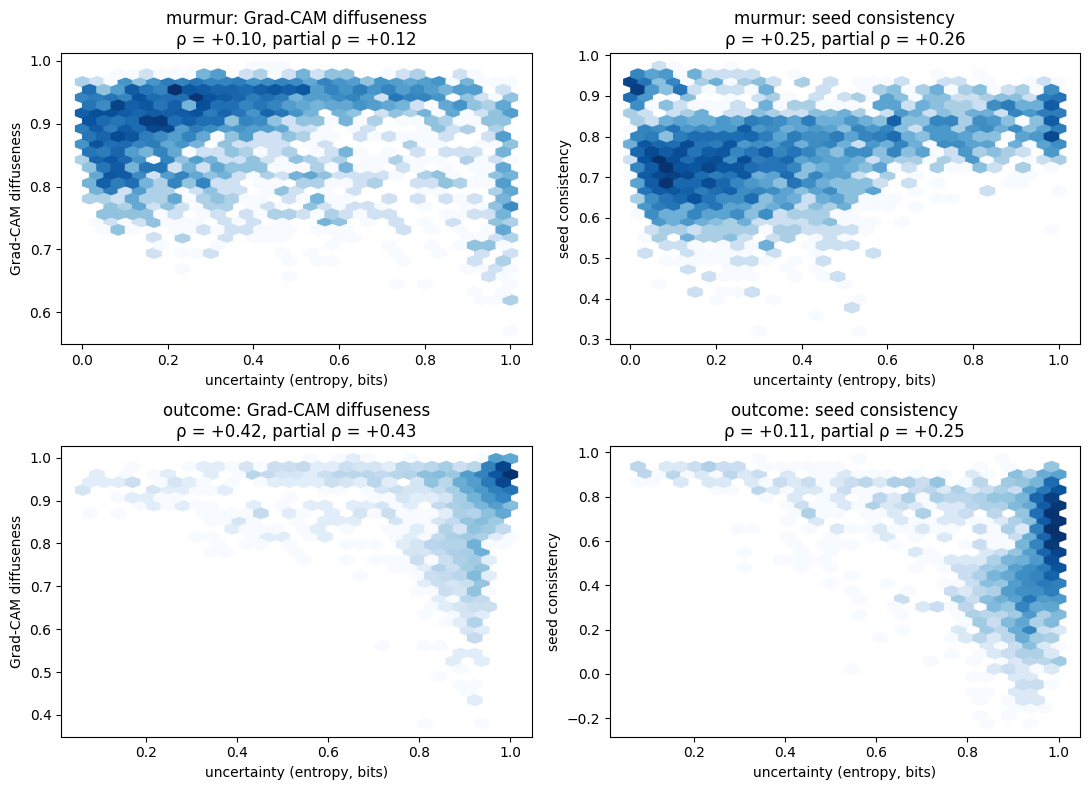

In [10]:
c_rows = []
for task, key in [("murmur", "m"), ("outcome", "o")]:
    for unc in ["entropy", "risk_chow", "ens_std"]:
        for feat in [f"diffuseness_cam_{key}", f"gini_cam_{key}", f"consistency_{key}", f"diffuseness_gx_{key}", f"gini_gx_{key}"]:
            if unc != "entropy" and not feat.startswith(("diffuseness_cam", "consistency")):
                continue
            c_rows.append(corr_test(REC, f"{task}_{unc}", feat, {"task": task, "uncertainty": unc, "feature": feat.rsplit("_", 1)[0]}))
corr12 = pd.DataFrame(c_rows)
corr12["ρ (95% CI)"] = [fmt_dci(r.spearman, r.spearman_lo, r.spearman_hi) for r in corr12.itertuples()]
corr12["partial ρ (95% CI)"] = [fmt_dci(r.partial, r.partial_lo, r.partial_hi) for r in corr12.itertuples()]
display(corr12.pivot_table(index=["task", "feature"], columns="uncertainty", values="partial ρ (95% CI)", aggfunc="first"))
display(corr12[corr12.uncertainty == "entropy"][["task", "feature", "n", "ρ (95% CI)", "partial ρ (95% CI)"]])

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (task, key) in enumerate([("murmur", "m"), ("outcome", "o")]):
    for j, (feat, lab) in enumerate([(f"diffuseness_cam_{key}", "Grad-CAM diffuseness"), (f"consistency_{key}", "seed consistency")]):
        ax = axes[i, j]
        d = REC[[f"{task}_entropy", feat]].dropna()
        ax.hexbin(d[f"{task}_entropy"], d[feat], gridsize=30, cmap="Blues", mincnt=1, bins="log")
        r = corr12[(corr12.task == task) & (corr12.uncertainty == "entropy") & (corr12.feature == feat.rsplit("_", 1)[0])].iloc[0]
        ax.set(title=f"{task}: {lab}\nρ = {r.spearman:+.2f}, partial ρ = {r.partial:+.2f}", xlabel="uncertainty (entropy, bits)", ylabel=lab)
plt.tight_layout(); plt.savefig(FIG_DIR / "rq5_sharpness_consistency.png", dpi=200); plt.show()

## 10. Test 3 — clinical alignment (murmur head): do the maps fall on systole, and does that degrade with uncertainty?

*Components: ⑤ × clinical taxonomy × ④.*

Target set: Present patients with a systolic murmur, recordings at sites where it is audible, ≥ 2 s annotated.
- **Systole enrichment (Grad-CAM)** and **S1/S2 enrichment (gradient × input)**: mean with CI (1 = chance), for all target recordings and split by correct vs missed decisions.
- **Partial ρ(uncertainty, enrichment)** within the target set (negative = alignment degrades as uncertainty rises).
- Descriptive: phase shares of both maps for Absent recordings (correct decisions) and for the outcome head.

In [11]:
def mean_ci(v, groups):
    v = np.asarray(v, float); ok = ~np.isnan(v)
    v, g = v[ok], groups[ok]
    bis = boot_index_sets(g)
    bs = np.array([v[b].mean() for b in bis])
    return v.mean(), np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5), len(v)

TG = REC[REC.target].reset_index(drop=True)
a_rows = []
for subset, d in [("all target", TG), ("target, decision correct", TG[TG.murmur_correct == 1]), ("target, murmur missed", TG[TG.murmur_correct == 0])]:
    for feat in ["systole_enrichment_cam_m", "s1s2_enrichment_gx_m", "shap_systole_enrichment_m"]:
        m, lo, hi, n = mean_ci(d[feat].values, d.group.values)
        a_rows.append({"subset": subset, "feature": feat, "n": n, "mean (95% CI)": fmt_ci(m, lo, hi), "mean": m, "lo": lo, "hi": hi})
align = pd.DataFrame(a_rows)
display(align[["subset", "feature", "n", "mean (95% CI)"]])

a_corr = pd.DataFrame([corr_test(TG, f"murmur_{unc}", feat, {"uncertainty": unc, "feature": feat})
                       for unc in ["entropy", "risk_chow", "ens_std"] for feat in ["systole_enrichment_cam_m", "s1s2_enrichment_gx_m"]])
a_corr["partial ρ (95% CI)"] = [fmt_dci(r.partial, r.partial_lo, r.partial_hi) for r in a_corr.itertuples()]
a_corr["ρ (95% CI)"] = [fmt_dci(r.spearman, r.spearman_lo, r.spearman_hi) for r in a_corr.itertuples()]
display(a_corr[["uncertainty", "feature", "n", "ρ (95% CI)", "partial ρ (95% CI)"]])

desc = []
groups_desc = {"murmur head, target (systolic, audible)": (TG, "m"),
               "murmur head, Absent, correct": (REC[(REC.murmur == "Absent") & (REC.murmur_correct == 1) & (REC.annotated_s >= cfg.min_annotated_sec)], "m"),
               "outcome head, Abnormal, correct": (REC[(REC.y_outcome == 1) & (REC.outcome_correct == 1) & (REC.annotated_s >= cfg.min_annotated_sec)], "o"),
               "outcome head, Normal, correct": (REC[(REC.y_outcome == 0) & (REC.outcome_correct == 1) & (REC.annotated_s >= cfg.min_annotated_sec)], "o")}
for name, (d, key) in groups_desc.items():
    row = {"group": name, "n": len(d)}
    for ph in PHASES:
        row[f"time {ph}"] = d[f"time_share_{ph}"].mean()
        row[f"Grad-CAM {ph}"] = d[f"cam_share_{ph}_{key}"].mean()
        row[f"grad×input {ph}"] = d[f"gx_share_{ph}_{key}"].mean()
        row[f"SHAP φ {ph}"] = d[f"shap_{ph}_{key}"].mean()
    desc.append(row)
phase_desc = pd.DataFrame(desc)
display(phase_desc.round(3).T)

,subset,feature,n,mean (95% CI)
0,all target,systole_enrichment_cam_m,496,"1.585 [1.524, 1.644]"
1,all target,s1s2_enrichment_gx_m,496,"1.182 [1.166, 1.200]"
2,all target,shap_systole_enrichment_m,496,"1.405 [1.357, 1.453]"
3,"target, decision correct",systole_enrichment_cam_m,432,"1.674 [1.618, 1.731]"
4,"target, decision correct",s1s2_enrichment_gx_m,432,"1.168 [1.153, 1.185]"
5,"target, decision correct",shap_systole_enrichment_m,432,"1.399 [1.353, 1.445]"
6,"target, murmur missed",systole_enrichment_cam_m,64,"0.989 [0.922, 1.062]"
7,"target, murmur missed",s1s2_enrichment_gx_m,64,"1.276 [1.226, 1.328]"
8,"target, murmur missed",shap_systole_enrichment_m,64,"1.445 [1.264, 1.615]"


,uncertainty,feature,n,ρ (95% CI),partial ρ (95% CI)
0,entropy,systole_enrichment_cam_m,496,"-0.178 [-0.282, -0.061]","-0.138 [-0.243, -0.015]"
1,entropy,s1s2_enrichment_gx_m,496,"-0.065 [-0.203, +0.049]","-0.069 [-0.207, +0.046]"
2,risk_chow,systole_enrichment_cam_m,496,"-0.329 [-0.423, -0.224]","-0.282 [-0.381, -0.173]"
3,risk_chow,s1s2_enrichment_gx_m,496,"-0.036 [-0.173, +0.080]","-0.053 [-0.200, +0.071]"
4,ens_std,systole_enrichment_cam_m,496,"-0.241 [-0.330, -0.140]","-0.215 [-0.311, -0.108]"
5,ens_std,s1s2_enrichment_gx_m,496,"-0.025 [-0.145, +0.084]","-0.042 [-0.169, +0.071]"


,0,1,2,3
group,"murmur head, target (systolic, audible)","murmur head, Absent, correct","outcome head, Abnormal, correct","outcome head, Normal, correct"
n,496,2137,1186,554
time S1,0.207,0.201,0.205,0.203
Grad-CAM S1,0.278,0.165,0.242,0.182
grad×input S1,0.279,0.268,0.272,0.235
SHAP φ S1,1.664,-0.063,0.005,0.417
time systole,0.23,0.238,0.239,0.232
Grad-CAM systole,0.359,0.263,0.291,0.289
grad×input systole,0.313,0.215,0.301,0.21
SHAP φ systole,1.99,-0.634,0.13,0.26


## 11. Test 4 — sharp but wrong? Wrong vs correct decisions at matched confidence

*Components: ⑤ × ④.*

Wrong decisions are, on average, less confident, so comparing them directly with correct ones mixes two effects. Here labelled recordings are split into **fifths of uncertainty** (entropy); within each fifth, the mean of wrong minus correct is taken, and fifths are combined weighted by their number of wrong decisions. Positive diffuseness difference = wrong decisions get *more diffuse* maps than correct ones at the same confidence (explanations signal the error); ≈ 0 or negative = wrong decisions look as sharp as correct ones.

In [12]:
def matched_diff(df, task, feat):
    d = df[df[f"{task}_correct"].notna() & df[feat].notna()]
    q = pd.qcut(rankdata(d[f"{task}_entropy"].values, method="ordinal"), 5, labels=False)
    wrong = d[f"{task}_correct"].values == 0
    x = d[feat].values
    def stat(ix):
        num, den = 0.0, 0
        for k in range(5):
            m = q[ix] == k
            w_, c_ = x[ix][m & wrong[ix]], x[ix][m & ~wrong[ix]]
            if len(w_) and len(c_):
                num += len(w_) * (w_.mean() - c_.mean()); den += len(w_)
        return num / den if den else np.nan
    full = np.arange(len(d))
    bs = np.array([stat(b) for b in boot_index_sets(d.group.values)])
    return {"task": task, "feature": feat, "n": len(d), "n wrong": int(wrong.sum()), "difference": stat(full),
            "ci_low": np.nanpercentile(bs, 2.5), "ci_high": np.nanpercentile(bs, 97.5)}

m_rows = []
for task, key in [("murmur", "m"), ("outcome", "o")]:
    for feat in [f"diffuseness_cam_{key}", f"consistency_{key}", f"diffuseness_gx_{key}"]:
        m_rows.append(matched_diff(REC, task, feat))
m_rows.append({**matched_diff(TG, "murmur", "systole_enrichment_cam_m"), "feature": "systole_enrichment_cam_m (target set)"})
matched = pd.DataFrame(m_rows)
matched["wrong − correct (95% CI)"] = [fmt_dci(r.difference, r.ci_low, r.ci_high) for r in matched.itertuples()]
display(matched[["task", "feature", "n", "n wrong", "wrong − correct (95% CI)"]])

,task,feature,n,n wrong,wrong − correct (95% CI)
0,murmur,diffuseness_cam_m,3007,391,"-0.020 [-0.037, -0.004]"
1,murmur,consistency_m,3007,391,"-0.011 [-0.023, -0.000]"
2,murmur,diffuseness_gx_m,3007,391,"-0.005 [-0.006, -0.003]"
3,outcome,diffuseness_cam_o,3163,1416,"+0.001 [-0.005, +0.007]"
4,outcome,consistency_o,3147,1409,"-0.026 [-0.045, -0.006]"
5,outcome,diffuseness_gx_o,3163,1416,"-0.000 [-0.001, +0.001]"
6,murmur,systole_enrichment_cam_m (target set),496,64,"-0.713 [-0.823, -0.597]"


## 12. Test 5 — phase-SHAP: what does the model actually use, and does Grad-CAM agree?

*Component ⑤, model-agnostic.*

- Mean φ per phase (decision-direction logit units) for the target set, split by correct vs missed, with CIs.
- Share of target recordings in which **systole** has the largest φ.
- Agreement: Spearman between Grad-CAM systole enrichment and SHAP systole enrichment across target recordings.

In [13]:
s_rows = []
for subset, d in [("target, decision correct", TG[TG.murmur_correct == 1]), ("target, murmur missed", TG[TG.murmur_correct == 0]),
                  ("Absent, correct", REC[(REC.murmur == "Absent") & (REC.murmur_correct == 1) & (REC.annotated_s >= cfg.min_annotated_sec)])]:
    row = {"subset": subset}
    for ph in PHASES:
        m, lo, hi, n = mean_ci(d[f"shap_{ph}_m"].values, d.group.values)
        row[f"φ {ph}"] = fmt_dci(m, lo, hi); row["n"] = n
    phis = d[[f"shap_{ph}_m" for ph in PHASES]].dropna().values
    row["systole largest φ"] = f"{np.mean(phis.argmax(1) == 1):.1%}" if len(phis) else ""
    s_rows.append(row)
shap_tab = pd.DataFrame(s_rows)
display(shap_tab)
d = TG[["systole_enrichment_cam_m", "shap_systole_enrichment_m", "group"]].dropna()
bs = np.array([spearman(d.systole_enrichment_cam_m.values[b], d.shap_systole_enrichment_m.values[b]) for b in boot_index_sets(d.group.values)])
agree = {"n": len(d), "spearman": spearman(d.systole_enrichment_cam_m.values, d.shap_systole_enrichment_m.values),
         "ci_low": np.nanpercentile(bs, 2.5), "ci_high": np.nanpercentile(bs, 97.5)}
print(f"Grad-CAM vs phase-SHAP systole enrichment (target set): ρ = {fmt_dci(agree['spearman'], agree['ci_low'], agree['ci_high'])}, n = {agree['n']}")

,subset,φ S1,n,φ systole,φ S2,φ diastole,systole largest φ
0,"target, decision correct","+1.948 [+1.818, +2.071]",432,"+2.414 [+2.259, +2.556]","+1.363 [+1.244, +1.483]","+2.134 [+1.984, +2.294]",56.0%
1,"target, murmur missed","-0.252 [-0.387, -0.133]",64,"-0.873 [-1.060, -0.694]","-0.049 [-0.184, +0.078]","-0.971 [-1.235, -0.715]",6.2%
2,"Absent, correct","-0.063 [-0.094, -0.033]",2137,"-0.634 [-0.670, -0.599]","-0.077 [-0.105, -0.047]","-0.837 [-0.881, -0.792]",7.1%


Grad-CAM vs phase-SHAP systole enrichment (target set): ρ = +0.326 [+0.199, +0.441], n = 496


## 13. Case studies (pre-set selection)

*Component ⑤ — the methods document's qualitative case studies.*

1. The **10 most uncertain** target recordings among those with **systole enrichment below 1** (the map is *not* on systole).
2. The **10 most confident wrong** murmur decisions (lowest entropy among wrong decisions).

Each panel: the waveform (first 10 s) with the annotated phases shaded, the Grad-CAM and gradient × input time profiles for the murmur head.

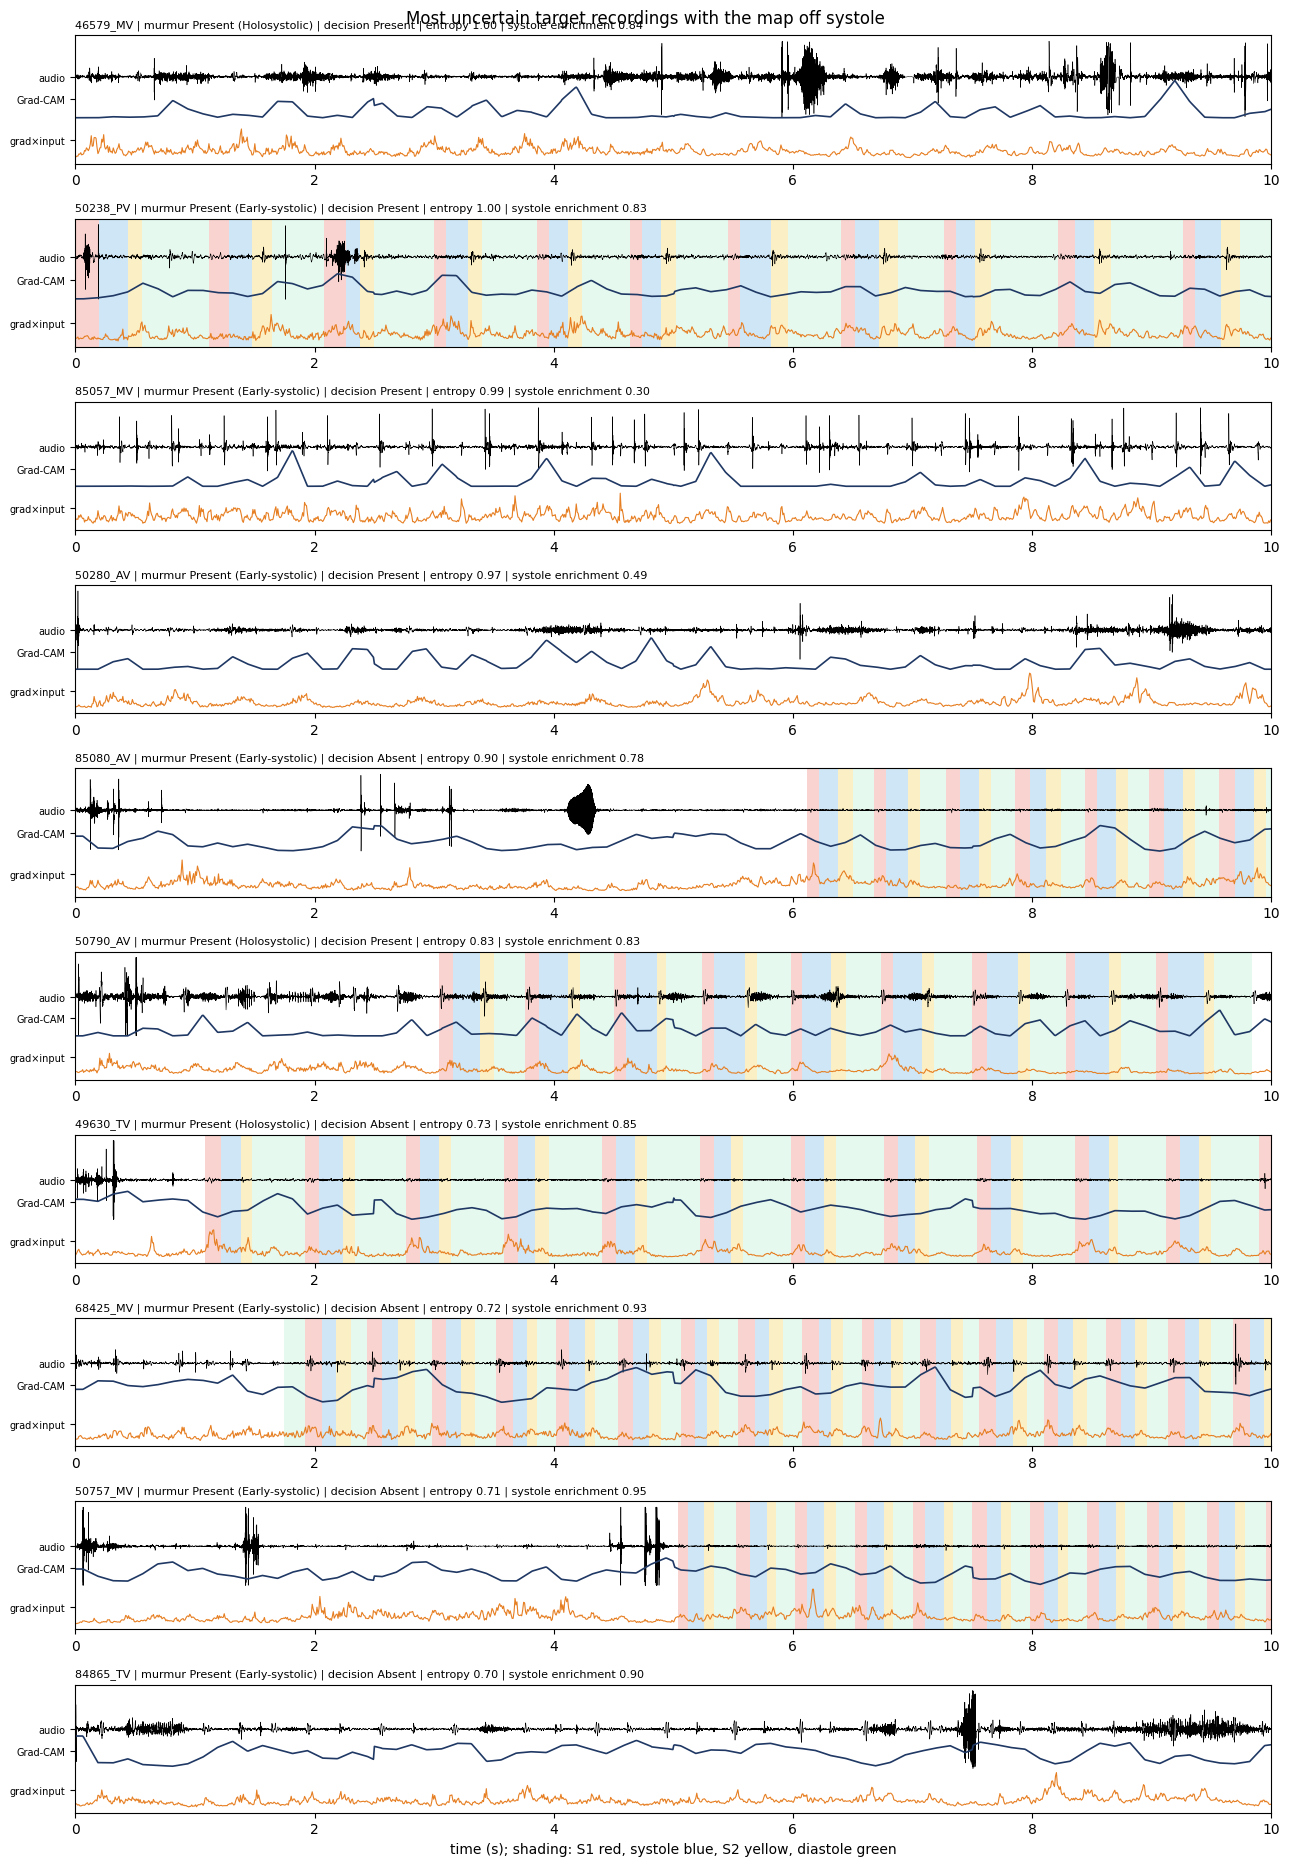

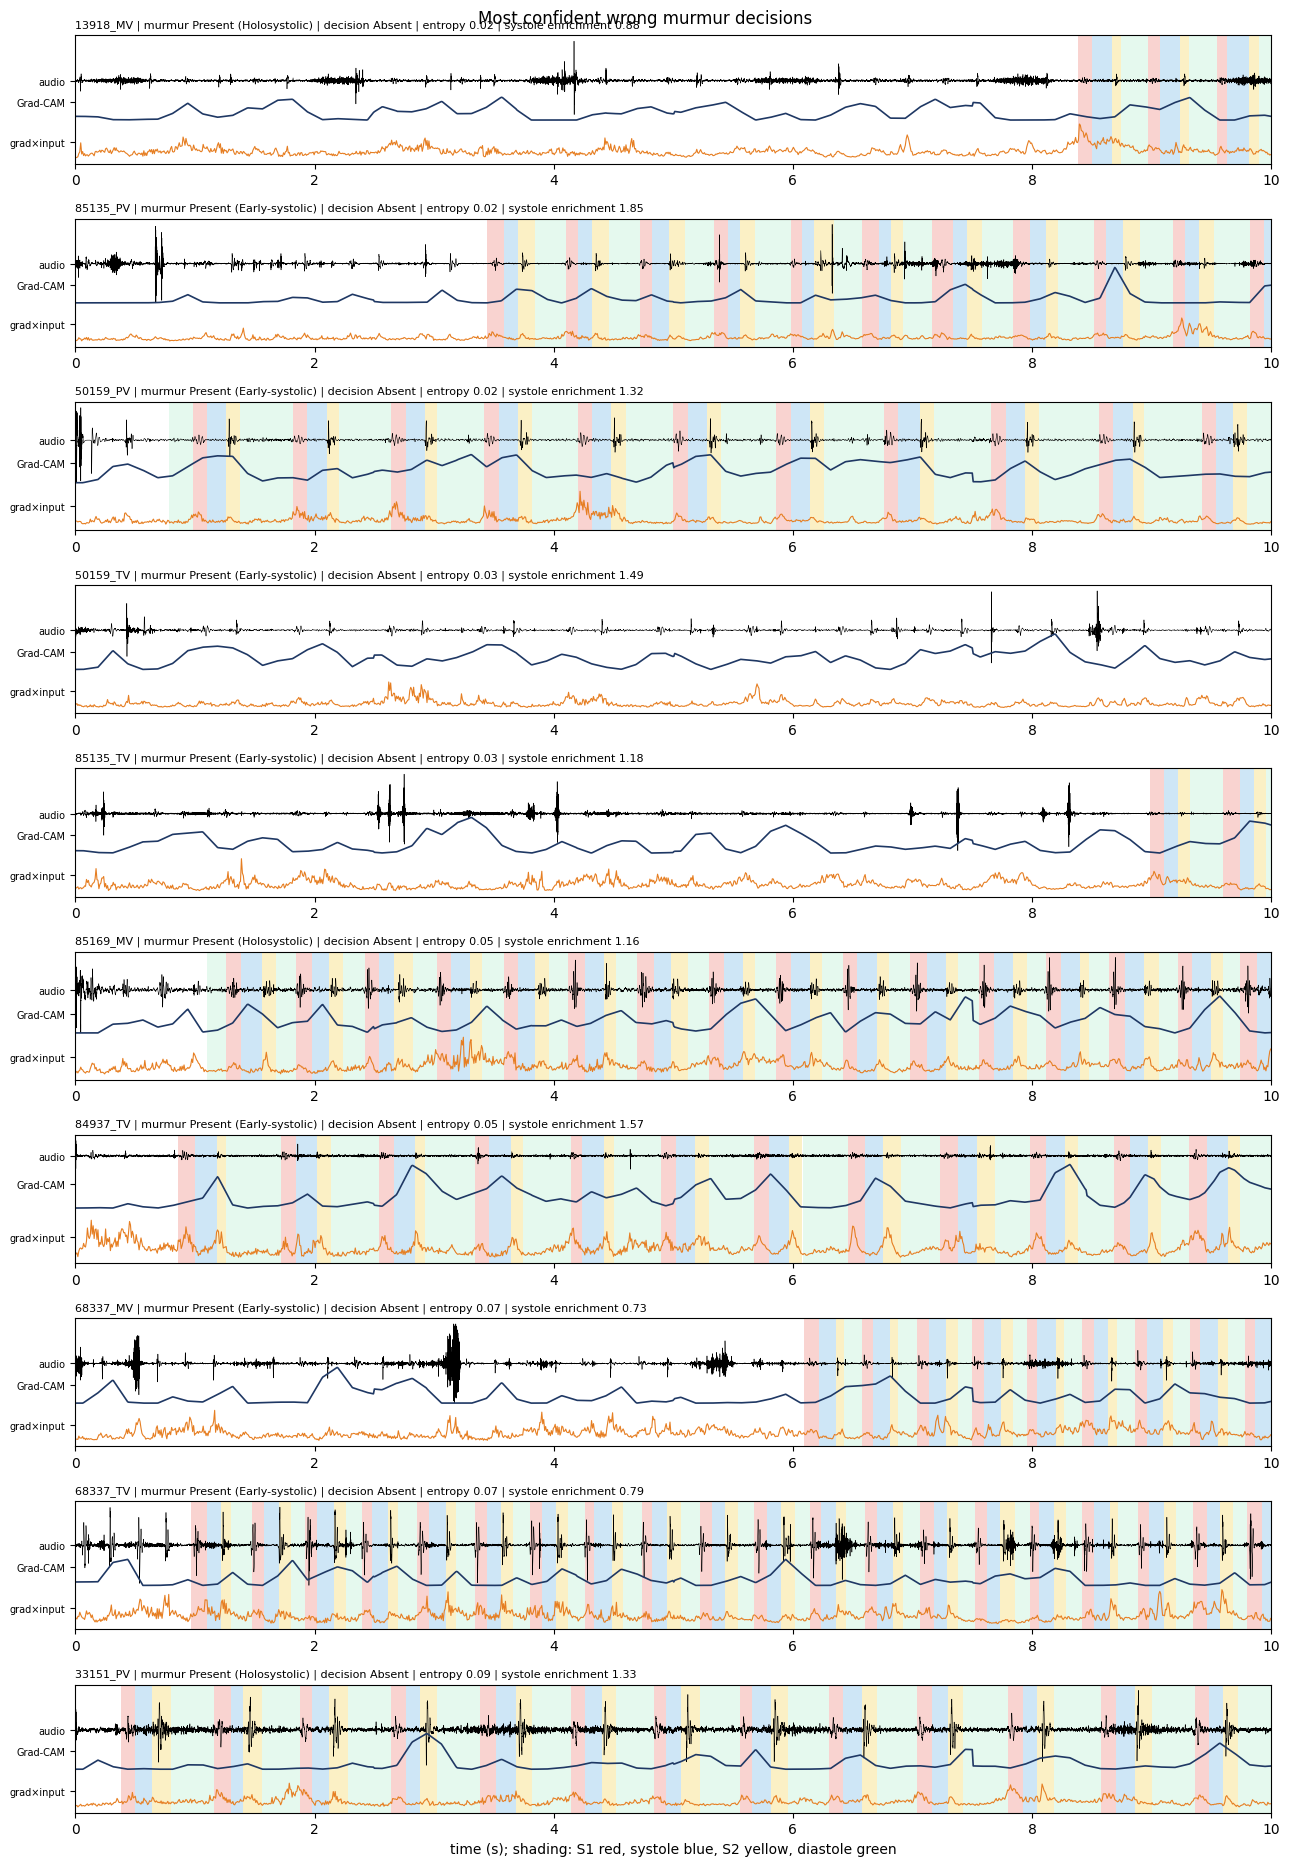

In [14]:
def recording_profiles(i, key="m"):
    n_fr = int(math.ceil(REC_LEN[i] / HOP_F))
    acc_cam, acc_gx, cnt = np.zeros(n_fr), np.zeros(n_fr), np.zeros(n_fr)
    for j in rec_windows[i]:
        s0 = int(round(win_start[j] / HOP_F)); e0 = min(s0 + N_FR, n_fr); L = e0 - s0
        if L <= 0:
            continue
        acc_cam[s0:e0] += np.interp(FRAME_POS, BIN_CENTRES, W[f"cam_{key}"][j])[:L]
        acc_gx[s0:e0] += W[f"gx_{key}"][j][:L]; cnt[s0:e0] += 1
    return acc_cam / np.maximum(cnt, 1), acc_gx / np.maximum(cnt, 1)

cand1 = REC[REC.target & (REC.systole_enrichment_cam_m < 1)].sort_values("murmur_entropy", ascending=False).head(cfg.n_cases)
cand2 = REC[REC.murmur_correct == 0].sort_values("murmur_entropy").head(cfg.n_cases)
PH_COL = {1: "#F5B7B1", 2: "#AED6F1", 3: "#F9E79F", 4: "#D5F5E3"}
for title, cand, fname in [("Most uncertain target recordings with the map off systole", cand1, "rq5_cases_uncertain_misaligned.png"),
                           ("Most confident wrong murmur decisions", cand2, "rq5_cases_confident_wrong.png")]:
    if len(cand) == 0:
        print("no recordings for:", title); continue
    fig, axes = plt.subplots(len(cand), 1, figsize=(13, 1.9 * len(cand)), squeeze=False)
    for ax, (i, r) in zip(axes[:, 0], cand.iterrows()):
        sr = cfg.sample_rate; nshow = min(REC_LEN[i], 10 * sr)
        t = np.arange(nshow) / sr
        a = AUDIO[i][:nshow]
        for st, en, c in SEG[i]:
            if c > 0 and st < 10:
                ax.axvspan(st, min(en, 10), color=PH_COL[int(c)], alpha=0.6, lw=0)
        ax.plot(t, a / (np.abs(a).max() + 1e-9), color="black", lw=0.4)
        cam, gx = recording_profiles(i)
        tf = (np.arange(len(cam)) * HOP_F + HOP_F / 2) / sr
        m = tf < 10
        ax.plot(tf[m], cam[m] / (cam.max() + 1e-9) * 0.9 - 1.0, color=NAVY, lw=1.2)
        ax.plot(tf[m], gx[m] / (gx.max() + 1e-9) * 0.9 - 2.0, color=ORANGE, lw=0.8)
        ax.set_yticks([0, -0.55, -1.55]); ax.set_yticklabels(["audio", "Grad-CAM", "grad×input"], fontsize=7)
        ax.set_xlim(0, 10)
        ax.set_title(f"{r.wid} | murmur {r.murmur} ({r.systolic_timing}) | decision {'Present' if r.murmur_pred == 1 else 'Absent'} | "
                     f"entropy {r.murmur_entropy:.2f} | systole enrichment {r.systole_enrichment_cam_m:.2f}", fontsize=8, loc="left")
    axes[-1, 0].set_xlabel("time (s); shading: S1 red, systole blue, S2 yellow, diastole green")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=150); plt.show()

## 14. The pre-set answer rule, applied

*Components: ⑤ × ④ → RQ5's answer.*

Per head, with Grad-CAM and entropy (primary):

| verdict | condition (95 % CIs) |
|---|---|
| **honest uncertainty** | partial ρ(uncertainty, diffuseness) > 0 **or** partial ρ(uncertainty, seed consistency) < 0 |
| **reverse** | partial ρ(uncertainty, diffuseness) < 0 (more uncertain → sharper) |
| **unreliable explanations** | not honest (or reverse) **and** wrong decisions not more diffuse than correct ones at matched confidence |
| **alignment degrades with confidence** (murmur) | partial ρ(uncertainty, systole enrichment) < 0 in the target set |

The model-randomisation check must pass for any of these to be interpreted.

In [15]:
def g(task, feat, unc="entropy"):
    return corr12[(corr12.task == task) & (corr12.uncertainty == unc) & (corr12.feature == feat)].iloc[0]

san_pass = bool(san_sum[(san_sum.randomised.str.startswith("(b)")) & (san_sum["map"] == "Grad-CAM")]["median"].iloc[0] < 0.5)
ans = []
for task, key in [("murmur", "m"), ("outcome", "o")]:
    dif, con = g(task, f"diffuseness_cam_{key}".rsplit("_", 1)[0]), g(task, f"consistency_{key}".rsplit("_", 1)[0])
    md_ = matched[(matched.task == task) & (matched.feature == f"diffuseness_cam_{key}")].iloc[0]
    honest_d, honest_c = dif.partial_lo > 0, con.partial_hi < 0
    reverse = dif.partial_hi < 0
    wrong_not_diffuse = not (md_.ci_low > 0)
    honest = honest_d or honest_c
    if honest and not reverse:
        verdict = "honest uncertainty"
    elif honest and reverse:
        verdict = "mixed (less consistent but sharper when uncertain)"
    elif wrong_not_diffuse:
        verdict = "unreliable explanations"
    else:
        verdict = "inconclusive"
    ans.append({"task": task, "partial ρ (uncertainty, diffuseness)": dif["partial ρ (95% CI)"],
                "partial ρ (uncertainty, consistency)": con["partial ρ (95% CI)"],
                "wrong − correct diffuseness, matched": md_["wrong − correct (95% CI)"], "verdict": verdict,
                "sanity check passed": san_pass})
answer = pd.DataFrame(ans)
ac = a_corr[(a_corr.uncertainty == "entropy") & (a_corr.feature == "systole_enrichment_cam_m")].iloc[0]
al = align[(align.subset == "all target") & (align.feature == "systole_enrichment_cam_m")].iloc[0]
alignment_verdict = {"systole enrichment, target (Grad-CAM)": al["mean (95% CI)"],
                     "partial ρ (uncertainty, systole enrichment)": ac["partial ρ (95% CI)"],
                     "alignment degrades with confidence": bool(ac.partial_hi < 0),
                     "maps on systole above chance": bool(al.lo > 1)}
display(answer)
print(alignment_verdict)

,task,"partial ρ (uncertainty, diffuseness)","partial ρ (uncertainty, consistency)","wrong − correct diffuseness, matched",verdict,sanity check passed
0,murmur,"+0.125 [+0.068, +0.182]","+0.256 [+0.210, +0.302]","-0.020 [-0.037, -0.004]",honest uncertainty,True
1,outcome,"+0.431 [+0.390, +0.471]","+0.253 [+0.198, +0.308]","+0.001 [-0.005, +0.007]",honest uncertainty,True


{'systole enrichment, target (Grad-CAM)': '1.585 [1.524, 1.644]', 'partial ρ (uncertainty, systole enrichment)': '-0.138 [-0.243, -0.015]', 'alignment degrades with confidence': True, 'maps on systole above chance': True}


## 15. Save

| file | contents | used by |
|---|---|---|
| `units_xai/xai_f*_s*.npz` | per-window Grad-CAM, gradient × input and phase-SHAP, both heads, every seed | RQ6 (XAI module), report |
| `rq5_recording_metrics.csv` | per recording: diffuseness, Gini, consistency, phase shares, enrichments, phase-SHAP, decisions, confidence, target flag | report, RQ6 |
| `rq5_sanity.csv`, `rq5_correlations.csv`, `rq5_alignment.csv`, `rq5_alignment_correlations.csv`, `rq5_phase_shares.csv`, `rq5_matched.csv`, `rq5_shap.csv`, `rq5_answer.csv` | the tests | report |

In [16]:
REC.drop(columns=[]).to_csv(OUT / "rq5_recording_metrics.csv", index=False)
san_sum.to_csv(OUT / "rq5_sanity.csv", index=False)
corr12.to_csv(OUT / "rq5_correlations.csv", index=False)
align.to_csv(OUT / "rq5_alignment.csv", index=False)
a_corr.to_csv(OUT / "rq5_alignment_correlations.csv", index=False)
phase_desc.to_csv(OUT / "rq5_phase_shares.csv", index=False)
matched.to_csv(OUT / "rq5_matched.csv", index=False)
shap_tab.assign(gradcam_shap_agreement=fmt_dci(agree["spearman"], agree["ci_low"], agree["ci_high"])).to_csv(OUT / "rq5_shap.csv", index=False)
answer.assign(**{k: str(v) for k, v in alignment_verdict.items()}).to_csv(OUT / "rq5_answer.csv", index=False)
for p_ in sorted(OUT.rglob("*")):
    if p_.is_file():
        print(f"  {p_.relative_to(OUT)}  ({p_.stat().st_size / 1e6:.2f} MB)")

  figures/rq5_cases_confident_wrong.png  (1.18 MB)
  figures/rq5_cases_uncertain_misaligned.png  (1.09 MB)
  figures/rq5_sharpness_consistency.png  (0.43 MB)
  rq5_alignment.csv  (0.00 MB)
  rq5_alignment_correlations.csv  (0.00 MB)
  rq5_answer.csv  (0.00 MB)
  rq5_correlations.csv  (0.00 MB)
  rq5_matched.csv  (0.00 MB)
  rq5_phase_shares.csv  (0.00 MB)
  rq5_recording_metrics.csv  (3.71 MB)
  rq5_sanity.csv  (0.00 MB)
  rq5_shap.csv  (0.00 MB)
  units_xai/xai_f0_s123.npz  (22.31 MB)
  units_xai/xai_f0_s42.npz  (22.57 MB)
  units_xai/xai_f0_s7.npz  (22.44 MB)
  units_xai/xai_f1_s123.npz  (21.85 MB)
  units_xai/xai_f1_s42.npz  (21.68 MB)
  units_xai/xai_f1_s7.npz  (21.60 MB)
  units_xai/xai_f2_s123.npz  (21.31 MB)
  units_xai/xai_f2_s42.npz  (21.31 MB)
  units_xai/xai_f2_s7.npz  (21.19 MB)


In [17]:
# RQ5 section 16 - exploratory follow-up. Paste each block below as a new cell at the END of the notebook,
# in the same session (after section 15). Markdown blocks are optional.

# %% ===== CELL 1 (markdown) =====
# ## 16. Follow-up (exploratory, not pre-registered)
# 
# *Components: ⑤ × ④. Added after reading the results; nothing above changes. The pre-set answer in section 14 stays the primary answer.*
# 
# Run in the same session after section 15 (it uses `REC`, `TG`, `W`, `SEG`, the saved units and the helpers above). No GPU needed.
# 
# **Part A** reproduces the checks already run on `rq5_recording_metrics.csv`:
# - A1: Grad-CAM systole focus by decision type (correct Present, false Present, correct Absent, missed).
# - A2: within correct Present decisions, does systole focus fall as uncertainty rises?
# - A3: tests 1 and 2 split by **decision direction**, and with map spread added as a control. The *all decisions* rows must reproduce section 9.
# - A4: Absent decisions. Does the map move towards or away from systole as uncertainty rises, and is seed agreement related to systole focus?
# 
# **Part B** tests two explanations that need the maps themselves. The predictions were written before running.
# 
# | | Explanation | Measure (murmur head, per window, then averaged per recording) | Prediction |
# |---|---|---|---|
# | B-1 | For Present decisions, a clear murmur repeats on every beat, so the map covers several systoles and counts as "diffuse". An uncertain Present decision rests on one beat, and each seed picks a different beat. | **beat coverage**: share of the window's systoles with Grad-CAM density above the window's annotated mean. **single-beat concentration**: (top systole's share − 1/n) / (1 − 1/n); 0 = equal across beats, 1 = one beat. **seed beat agreement**: share of seed pairs whose highest-density systole is the same beat (chance ≈ 1/n). | entropy vs coverage < 0; entropy vs concentration > 0; spread vs coverage > 0; entropy vs spread moves towards 0 when coverage is controlled; entropy vs seed beat agreement < 0 |
# | B-2 | For Absent decisions, confident maps are **sparse** (ReLU leaves many time bins at exactly zero), and sparse maps from different seeds overlap less, which lowers the Spearman agreement. | **sparsity**: share of the 40 time bins with no positive evidence, per seed map, averaged over seeds | murmur Absent: entropy vs sparsity < 0; sparsity vs agreement < 0; entropy vs agreement moves towards 0 when sparsity is controlled |
# 
# Systoles count only with ≥ 80 ms inside the window, and windows need ≥ 2 of them. Grad-CAM's time resolution is 0.125 s, so beat-level measures are coarse. Paediatric systole is about 0.15–0.3 s.

# %% ===== CELL 2 (code) =====
# 16.1 helpers
def corr_test_x(df, xcol, ycol, label, extra=()):
    # partial Spearman with the section-8 controls, plus optional extra controls (ranked); same 1,000 patient-group resamples
    cols = list(dict.fromkeys([xcol, ycol, *extra, "p_good", "y_murmur", "y_outcome", "group"]))
    d = df[cols].dropna().reset_index(drop=True)
    x, y = d[xcol].values, d[ycol].values
    def C(dd):
        base = covars(dd)
        if not extra:
            return base
        return np.column_stack([base, np.column_stack([rankdata(dd[e].values) for e in extra]).astype(float)])
    par = partial_spearman(x, y, C(d))
    bp = np.array([partial_spearman(x[b], y[b], C(d.iloc[b])) for b in boot_index_sets(d.group.values)])
    lo, hi = np.nanpercentile(bp, 2.5), np.nanpercentile(bp, 97.5)
    return {**label, "x": xcol, "y": ycol, "controls added": " + ".join(extra), "n": len(d),
            "partial": par, "lo": lo, "hi": hi, "partial ρ (95% CI)": fmt_dci(par, lo, hi)}

def T(d, x, y, lab, test, extra=()):
    return corr_test_x(d, x, y, {**lab, "test": test}, extra)

ANN = REC.annotated_s >= cfg.min_annotated_sec
DEC_NAME = {("murmur", 1): "Present", ("murmur", 0): "Absent", ("outcome", 1): "Abnormal", ("outcome", 0): "Normal"}

# %% ===== CELL 3 (markdown) =====
# ### Part A — checks on the recording metrics

# %% ===== CELL 4 (code) =====
# A1. Grad-CAM systole focus by decision type (murmur head)
dt_sets = {"correct Present (target)": TG[TG.murmur_pred == 1],
           "false Present (Absent patients)": REC[(REC.murmur == "Absent") & (REC.murmur_pred == 1) & ANN],
           "correct Absent (Absent patients)": REC[(REC.murmur == "Absent") & (REC.murmur_pred == 0) & ANN],
           "missed (target)": TG[TG.murmur_pred == 0]}
dt_rows = []
for name, d in dt_sets.items():
    m, lo, hi, n = mean_ci(d.systole_enrichment_cam_m.values, d.group.values)
    dt_rows.append({"decision type": name, "n": n, "Grad-CAM systole enrichment (95% CI)": fmt_ci(m, lo, hi),
                    "median entropy": round(float(d.murmur_entropy.median()), 3)})
dec_type = pd.DataFrame(dt_rows)
display(dec_type)

# A2. within correct Present decisions (target set)
a2 = corr_test(TG[TG.murmur_pred == 1], "murmur_entropy", "systole_enrichment_cam_m", {"set": "target, decided Present"})
print(f"A2  target, decided Present (n = {a2['n']}): ρ = {fmt_dci(a2['spearman'], a2['spearman_lo'], a2['spearman_hi'])}, "
      f"partial ρ = {fmt_dci(a2['partial'], a2['partial_lo'], a2['partial_hi'])}")

# A3. tests 1 and 2 split by decision direction, with map spread as an added control
split_rows = []
for task, key in [("murmur", "m"), ("outcome", "o")]:
    E, C_, D_ = f"{task}_entropy", f"consistency_{key}", f"diffuseness_cam_{key}"
    for dname, d in [("all decisions", REC)] + [(DEC_NAME[(task, v)], REC[REC[f"{task}_pred"] == v]) for v in (1, 0)]:
        lab = {"task": task, "decision": dname, "median seed agreement": round(float(d[C_].median()), 3)}
        split_rows += [T(d, E, D_, lab, "1 entropy vs diffuseness"),
                       T(d, E, C_, lab, "2 entropy vs seed agreement"),
                       T(d, E, C_, lab, "3 entropy vs seed agreement, controlling diffuseness", extra=(D_,)),
                       T(d, D_, C_, lab, "4 diffuseness vs seed agreement")]
split = pd.DataFrame(split_rows)
display(split.pivot_table(index=["task", "decision"], columns="test", values="partial ρ (95% CI)", aggfunc="first"))
display(split.drop_duplicates(["task", "decision"]).set_index(["task", "decision"])[["n", "median seed agreement"]])

# the section-14 rule applied within each group
v_rows = []
for (task, dname), g_ in split.groupby(["task", "decision"], sort=False):
    dif, con = g_[g_.test.str.startswith("1")].iloc[0], g_[g_.test.str.startswith("2")].iloc[0]
    honest, reverse = (dif.lo > 0) or (con.hi < 0), dif.hi < 0
    v_rows.append({"task": task, "decision": dname,
                   "verdict (section-14 rule)": "honest uncertainty" if honest and not reverse else
                   "mixed (less consistent but sharper when uncertain)" if honest and reverse else "neither signal"})
split_verdict = pd.DataFrame(v_rows)
display(split_verdict)

# A4. murmur Absent decisions: towards or away from systole as uncertainty rises?
dA = REC[(REC.murmur_pred == 0) & ANN]
absent_tab = pd.DataFrame([T(dA, "murmur_entropy", "systole_enrichment_cam_m", {"set": "decided Absent"}, "entropy vs systole enrichment"),
                           T(dA, "consistency_m", "systole_enrichment_cam_m", {"set": "decided Absent"}, "seed agreement vs systole enrichment")])
print(f"A4  decided Absent, ≥ {cfg.min_annotated_sec} s annotated: mean systole enrichment {dA.systole_enrichment_cam_m.mean():.3f}")
display(absent_tab[["set", "test", "n", "partial ρ (95% CI)"]])

# %% ===== CELL 5 (markdown) =====
# ### Part B — tests that need the maps
# 
# B-2 needs each seed's own Grad-CAM, so the saved units are read again. B-1 places each window's maps on the recording's annotated beats, as section 7 does.

# %% ===== CELL 6 (code) =====
# 16.3 per-seed maps, sparsity, beat-level measures
CAM_SEED = {key: np.zeros((len(cfg.seeds), N_WIN, 40), np.float32) for key in ["m", "o"]}
for f in range(cfg.n_folds):
    for si, s in enumerate(cfg.seeds):
        u = np.load(UNIT_DIR / f"xai_f{f}_s{s}.npz")
        for key in ["m", "o"]:
            CAM_SEED[key][si, u["widx"]] = u[f"cam_{key}"]

FU = REC.copy()
for key in ["m", "o"]:
    C3 = CAM_SEED[key]
    zero = C3 <= 1e-6 * C3.max(2, keepdims=True)              # an all-zero map counts as fully sparse
    sp_w = zero.mean(2).mean(0)                                # per window: share of time bins without evidence, mean of seeds
    FU[f"sparsity_{key}"] = [np.nanmean(sp_w[w]) for w in rec_windows]
display(FU[["sparsity_m", "sparsity_o"]].describe().round(3))

def systole_density(cam40, masks):
    prof = np.interp(FRAME_POS, BIN_CENTRES, cam40)
    return prof, np.array([prof[mk].mean() for mk in masks])

sr = cfg.sample_rate
pairs = [(0, 1), (0, 2), (1, 2)]
beat = {c: np.full(N_REC, np.nan) for c in ["beat_coverage_m", "single_beat_conc_m", "seed_beat_agreement_m", "beat_agree_chance_m", "n_beat_windows"]}
for i in tqdm(np.where(ANN.values)[0], desc="beat-level maps"):
    seg = SEG[i]
    if len(seg) == 0:
        continue
    cov, conc, agr, chance = [], [], [], []
    for j in rec_windows[i]:
        s0 = int(round(win_start[j] / HOP_F))
        t = ((s0 + FRAME_POS) * HOP_F + HOP_F / 2) / sr                 # same frame grid as section 7
        k = np.searchsorted(seg[:, 0], t, side="right") - 1
        kc = np.clip(k, 0, None)
        inside = (t * sr < REC_LEN[i]) & (k >= 0) & (t < seg[kc, 1])
        code_ = np.where(inside, seg[kc, 2], 0)
        ids, cnt = np.unique(k[code_ == 2], return_counts=True)
        ids = ids[cnt >= 10]                                             # systoles with ≥ 80 ms in this window
        if len(ids) < 2:
            continue
        masks = [(k == q) & (code_ == 2) for q in ids]
        ann = code_ > 0
        prof, d_ = systole_density(W["cam_m"][j], masks)                 # ensemble map
        ref = prof[ann].mean()
        if ref <= 0 or d_.sum() <= 0:
            continue
        n = len(d_)
        cov.append(np.mean(d_ > ref))
        conc.append((d_.max() / d_.sum() - 1 / n) / (1 - 1 / n))
        tops = []
        for si in range(len(cfg.seeds)):                                 # each seed's own map
            _, ds = systole_density(CAM_SEED["m"][si, j], masks)
            tops.append(int(np.argmax(ds)) if ds.max() > 0 else -1)
        ok = [(a, b) for a, b in pairs if tops[a] >= 0 and tops[b] >= 0]
        if ok:
            agr.append(np.mean([tops[a] == tops[b] for a, b in ok])); chance.append(1 / n)
    beat["n_beat_windows"][i] = len(cov)
    if cov:
        beat["beat_coverage_m"][i], beat["single_beat_conc_m"][i] = np.mean(cov), np.mean(conc)
    if agr:
        beat["seed_beat_agreement_m"][i], beat["beat_agree_chance_m"][i] = np.mean(agr), np.mean(chance)
for c, v in beat.items():
    FU[c] = v
print("recordings with beat-level measures:", int(FU.beat_coverage_m.notna().sum()))
display(FU[["beat_coverage_m", "single_beat_conc_m", "seed_beat_agreement_m", "beat_agree_chance_m", "n_beat_windows"]].describe().round(3))

# %% ===== CELL 7 (code) =====
# 16.4 tests
# B-1: Present decisions — one beat vs every beat
ta = []
for sname, d in [("target, decided Present", FU[FU.target & (FU.murmur_pred == 1)]),
                 ("all annotated, decided Present", FU[(FU.murmur_pred == 1) & ANN])]:
    lab = {"set": sname}
    ta += [T(d, "murmur_entropy", "beat_coverage_m", lab, "B1.1 entropy vs beat coverage (pred. < 0)"),
           T(d, "murmur_entropy", "single_beat_conc_m", lab, "B1.2 entropy vs single-beat concentration (pred. > 0)"),
           T(d, "diffuseness_cam_m", "beat_coverage_m", lab, "B1.3 diffuseness vs beat coverage (pred. > 0)"),
           T(d, "murmur_entropy", "diffuseness_cam_m", lab, "B1.4a entropy vs diffuseness"),
           T(d, "murmur_entropy", "diffuseness_cam_m", lab, "B1.4b entropy vs diffuseness, controlling beat coverage (pred. nearer 0)", extra=("beat_coverage_m",)),
           T(d, "murmur_entropy", "seed_beat_agreement_m", lab, "B1.5 entropy vs seeds choosing the same beat (pred. < 0)")]
    print(f"{sname}: seed beat agreement {d.seed_beat_agreement_m.mean():.3f} vs chance {d.beat_agree_chance_m.mean():.3f}")
beat_tests = pd.DataFrame(ta)
display(beat_tests.pivot_table(index="test", columns="set", values="partial ρ (95% CI)", aggfunc="first"))

# B-2: sparsity and seed agreement, by head and decision
tb = []
for task, key in [("murmur", "m"), ("outcome", "o")]:
    E, C_, S_, D_ = f"{task}_entropy", f"consistency_{key}", f"sparsity_{key}", f"diffuseness_cam_{key}"
    for v in (0, 1):
        d = FU[FU[f"{task}_pred"] == v]
        lab = {"task": task, "decision": DEC_NAME[(task, v)], "mean sparsity": round(float(d[S_].mean()), 3)}
        tb += [T(d, E, S_, lab, "B2.1 entropy vs sparsity"),
               T(d, S_, C_, lab, "B2.2 sparsity vs seed agreement"),
               T(d, E, C_, lab, "B2.3a entropy vs seed agreement"),
               T(d, E, C_, lab, "B2.3b same, controlling sparsity", extra=(S_,)),
               T(d, E, C_, lab, "B2.3c same, controlling sparsity + diffuseness", extra=(S_, D_))]
sparsity_tests = pd.DataFrame(tb)
display(sparsity_tests.pivot_table(index=["task", "decision"], columns="test", values="partial ρ (95% CI)", aggfunc="first"))
display(sparsity_tests.drop_duplicates(["task", "decision"]).set_index(["task", "decision"])[["n", "mean sparsity"]])

# %% ===== CELL 8 (code) =====
# 16.5 save
FU[["wid", "sparsity_m", "sparsity_o", "beat_coverage_m", "single_beat_conc_m", "seed_beat_agreement_m",
    "beat_agree_chance_m", "n_beat_windows"]].to_csv(OUT / "rq5_followup_recording.csv", index=False)
dec_type.to_csv(OUT / "rq5_followup_decision_type.csv", index=False)
split.to_csv(OUT / "rq5_followup_decision_split.csv", index=False)
split_verdict.to_csv(OUT / "rq5_followup_split_verdict.csv", index=False)
absent_tab.to_csv(OUT / "rq5_followup_absent.csv", index=False)
beat_tests.to_csv(OUT / "rq5_followup_beats.csv", index=False)
sparsity_tests.to_csv(OUT / "rq5_followup_sparsity.csv", index=False)
pd.DataFrame([a2]).to_csv(OUT / "rq5_followup_present_alignment.csv", index=False)
for p_ in sorted(OUT.glob("rq5_followup_*.csv")):
    print(" ", p_.name)

,decision type,n,Grad-CAM systole enrichment (95% CI),median entropy
0,correct Present (target),432,"1.674 [1.618, 1.731]",0.315
1,false Present (Absent patients),248,"1.374 [1.332, 1.418]",0.783
2,correct Absent (Absent patients),2137,"1.108 [1.095, 1.121]",0.236
3,missed (target),64,"0.989 [0.922, 1.062]",0.410


A2  target, decided Present (n = 432): ρ = -0.171 [-0.287, -0.049], partial ρ = -0.140 [-0.265, -0.004]


test                  1 entropy vs diffuseness 2 entropy vs seed agreement 3 entropy vs seed agreement, controlling diffuseness 4 diffuseness vs seed agreement
task    decision                                                                                                                                               
murmur  Absent         +0.464 [+0.413, +0.507]     +0.268 [+0.212, +0.315]                            +0.078 [+0.024, +0.126]           +0.443 [+0.402, +0.483]
        Present        -0.302 [-0.396, -0.198]     -0.386 [-0.465, -0.295]                            -0.347 [-0.430, -0.254]           +0.203 [+0.084, +0.300]
        all decisions  +0.125 [+0.068, +0.182]     +0.256 [+0.210, +0.302]                            +0.235 [+0.189, +0.281]           +0.236 [+0.189, +0.281]
outcome Abnormal       +0.086 [+0.034, +0.135]     -0.207 [-0.257, -0.149]                            -0.189 [-0.238, -0.135]           -0.472 [-0.518, -0.423]
        Normal         +0.230 [+0.139, +0.315]     +0.261 [+0.176, +0.334]                            +0.270 [+0.187, +0.343]           -0.010 [-0.093, +0.074]
        all decisions  +0.431 [+0.390, +0.471]     +0.253 [+0.198, +0.308]                            +0.230 [+0.177, +0.283]           +0.107 [+0.054, +0.157]

n  median seed agreement
task    decision                                  
murmur  all decisions  3163                  0.761
        Present         760                  0.874
        Absent         2403                  0.733
outcome all decisions  3163                  0.617
        Abnormal       2271                  0.693
        Normal          892                  0.376

,task,decision,verdict (section-14 rule)
0,murmur,all decisions,honest uncertainty
1,murmur,Present,mixed (less consistent but sharper when uncert...
2,murmur,Absent,honest uncertainty
3,outcome,all decisions,honest uncertainty
4,outcome,Abnormal,honest uncertainty
5,outcome,Normal,honest uncertainty


A4  decided Absent, ≥ 2.0 s annotated: mean systole enrichment 1.100


... (6 outputs left out)

set,"all annotated, decided Present","target, decided Present"
test,,
B1.1 entropy vs beat coverage (pred. < 0),"-0.465 [-0.546, -0.370]","-0.660 [-0.727, -0.570]"
B1.2 entropy vs single-beat concentration (pred. > 0),"+0.490 [+0.399, +0.571]","+0.715 [+0.633, +0.769]"
B1.3 diffuseness vs beat coverage (pred. > 0),"+0.131 [+0.021, +0.252]","+0.219 [+0.058, +0.373]"
B1.4a entropy vs diffuseness,"-0.305 [-0.399, -0.199]","-0.464 [-0.571, -0.324]"
"B1.4b entropy vs diffuseness, controlling beat coverage (pred. nearer 0)","-0.278 [-0.353, -0.190]","-0.437 [-0.521, -0.318]"
B1.5 entropy vs seeds choosing the same beat (pred. < 0),"+0.147 [+0.075, +0.223]","+0.186 [+0.094, +0.269]"


test             B2.1 entropy vs sparsity B2.2 sparsity vs seed agreement B2.3a entropy vs seed agreement B2.3b same, controlling sparsity B2.3c same, controlling sparsity + diffuseness
task    decision                                                                                                                                                                         
murmur  Absent    -0.476 [-0.521, -0.423]         -0.561 [-0.596, -0.524]         +0.268 [+0.212, +0.315]          +0.001 [-0.047, +0.043]                        +0.013 [-0.028, +0.053]
        Present   +0.184 [+0.081, +0.277]         -0.234 [-0.332, -0.121]         -0.386 [-0.465, -0.295]          -0.358 [-0.439, -0.264]                        -0.427 [-0.502, -0.341]
outcome Abnormal  +0.071 [+0.016, +0.126]         -0.284 [-0.340, -0.224]         -0.207 [-0.257, -0.149]          -0.195 [-0.248, -0.135]                        -0.147 [-0.204, -0.090]
        Normal    -0.285 [-0.366, -0.203]         -0.373 [-0.452, -0.294]         +0.261 [+0.176, +0.334]          +0.173 [+0.092, +0.246]                        +0.210 [+0.134, +0.285]

n  mean sparsity
task    decision                     
murmur  Absent    2403          0.196
        Present    760          0.234
outcome Normal     892          0.540
        Abnormal  2271          0.084

  rq5_followup_absent.csv
  rq5_followup_beats.csv
  rq5_followup_decision_split.csv
  rq5_followup_decision_type.csv
  rq5_followup_present_alignment.csv
  rq5_followup_recording.csv
  rq5_followup_sparsity.csv
  rq5_followup_split_verdict.csv
